# Loading

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import os

print("================================================================================")
print("LOADING PROCESSED MICROBIOME DATA - PYTHON")
print("================================================================================")

# Configuration - Update this path to match your data location
mypath = '/Users/mathieuvanhove/Desktop/Work/DeepImpact/Weeds_wheat/paper_1/data/matrice_phase1/'
df_dir = Path(mypath) / "df"

print(f"Loading data from: {df_dir.resolve()}")

# File paths
metadata_file = df_dir / "metadata_bacteria_1282ASVs.csv"
otu_count_file = df_dir / "otu_bacteria_table_R_1282ASVs.csv"
otu_normalized_file = df_dir / "otu_bacteria_normalized_v4.csv"
taxonomy_file = df_dir / "tax_bacteria_R_1282ASVs.csv"

# Check if files exist
files_to_check = {
    'metadata': metadata_file,
    'otu_count': otu_count_file,
    'otu_normalized': otu_normalized_file,
    'taxonomy': taxonomy_file
}

print("\n1. Checking file availability...")
missing_files = []
for name, filepath in files_to_check.items():
    if filepath.exists():
        print(f"✓ {name}: {filepath.name}")
    else:
        print(f"✗ {name}: {filepath.name} - FILE NOT FOUND")
        missing_files.append(name)

if missing_files:
    print(f"\n⚠️  Missing files: {missing_files}")
    print("Please ensure all files are generated from the previous processing step.")
    exit(1)

# ================================================================================
# 2. LOAD METADATA
# ================================================================================
print("\n2. Loading metadata...")

try:
    metadata_all = pd.read_csv(metadata_file)
    print(f"✓ Metadata loaded: {metadata_all.shape}")
    print(f"  Columns: {list(metadata_all.columns)}")
    print(f"  Sample types: {metadata_all.get('Sample_Type', pd.Series()).value_counts().to_dict()}")
except Exception as e:
    print(f"✗ Error loading metadata: {e}")
    exit(1)

# ================================================================================
# 3. LOAD OTU COUNT TABLE
# ================================================================================
print("\n3. Loading OTU count table...")

try:
    otu16_table = pd.read_csv(otu_count_file, sep='\t', index_col=0)
    print(f"✓ OTU count table loaded: {otu16_table.shape}")
    print(f"  ASV range: {otu16_table.index[0]} to {otu16_table.index[-1]}")
    print(f"  Sample range: {otu16_table.columns[0]} to {otu16_table.columns[-1]}")
    print(f"  Read count range: {otu16_table.min().min()} to {otu16_table.max().max()}")
    print(f"  Total reads: {otu16_table.sum().sum():,}")
except Exception as e:
    print(f"✗ Error loading OTU count table: {e}")
    exit(1)

# ================================================================================
# 4. LOAD OTU NORMALIZED TABLE
# ================================================================================
print("\n4. Loading OTU normalized table...")

try:
    otu_bacteria_normalized = pd.read_csv(otu_normalized_file, sep='\t', index_col=0)
    print(f"✓ OTU normalized table loaded: {otu_bacteria_normalized.shape}")
    print(f"  Value range: {otu_bacteria_normalized.min().min():.6f} to {otu_bacteria_normalized.max().max():.6f}")
    
    # Check normalization (should sum to 1 per sample)
    sample_sums = otu_bacteria_normalized.sum(axis=0)
    print(f"  Sample sums range: {sample_sums.min():.6f} to {sample_sums.max():.6f}")
    if np.allclose(sample_sums, 1.0, rtol=1e-3):
        print("  ✓ Normalization verified: all samples sum to 1.0")
    else:
        print("  ⚠️  Normalization warning: samples don't sum to exactly 1.0")
except Exception as e:
    print(f"✗ Error loading OTU normalized table: {e}")
    exit(1)

# ================================================================================
# 5. LOAD TAXONOMY TABLE
# ================================================================================
print("\n5. Loading taxonomy table...")

try:
    tax_df = pd.read_csv(taxonomy_file, sep='\t')
    print(f"✓ Taxonomy table loaded: {tax_df.shape}")
    print(f"  Taxonomic columns: {list(tax_df.columns)}")
    
    if 'Kingdom' in tax_df.columns:
        print(f"  Kingdom distribution: {tax_df['Kingdom'].value_counts().to_dict()}")
    if 'Phylum' in tax_df.columns:
        print(f"  Number of phyla: {tax_df['Phylum'].nunique()}")
        print(f"  Top 5 phyla: {tax_df['Phylum'].value_counts().head().to_dict()}")
except Exception as e:
    print(f"✗ Error loading taxonomy table: {e}")
    exit(1)

# ================================================================================
# 6. DATA SYNCHRONIZATION CHECKS
# ================================================================================
print("\n6. Performing data synchronization checks...")

# Check ASV synchronization
otu_asvs = set(otu16_table.index)
norm_asvs = set(otu_bacteria_normalized.index)
tax_asvs = set(tax_df['Cluster']) if 'Cluster' in tax_df.columns else set()

print(f"ASVs in count table: {len(otu_asvs)}")
print(f"ASVs in normalized table: {len(norm_asvs)}")
print(f"ASVs in taxonomy table: {len(tax_asvs)}")

if otu_asvs == norm_asvs:
    print("✓ Count and normalized tables have identical ASVs")
else:
    print("⚠️  Count and normalized tables have different ASVs")

if tax_asvs and otu_asvs <= tax_asvs:
    print("✓ All OTU ASVs have taxonomy information")
elif tax_asvs:
    missing_tax = otu_asvs - tax_asvs
    print(f"⚠️  {len(missing_tax)} ASVs missing taxonomy information")

# Check sample synchronization
otu_samples = set(otu16_table.columns)
norm_samples = set(otu_bacteria_normalized.columns)
meta_samples = set(metadata_all['sample']) if 'sample' in metadata_all.columns else set()

print(f"Samples in count table: {len(otu_samples)}")
print(f"Samples in normalized table: {len(norm_samples)}")
print(f"Samples in metadata: {len(meta_samples)}")

if otu_samples == norm_samples:
    print("✓ Count and normalized tables have identical samples")
else:
    print("⚠️  Count and normalized tables have different samples")

if meta_samples and otu_samples <= meta_samples:
    print("✓ All OTU samples have metadata information")
elif meta_samples:
    missing_meta = otu_samples - meta_samples
    print(f"⚠️  {len(missing_meta)} samples missing metadata information")

# ================================================================================
# 7. CREATE USEFUL DERIVED OBJECTS
# ================================================================================
print("\n7. Creating derived objects for analysis...")

# Create taxonomy dictionaries
if 'Cluster' in tax_df.columns:
    cluster_2_phylum_d = dict(zip(tax_df["Cluster"], tax_df["Phylum"])) if 'Phylum' in tax_df.columns else {}
    cluster_2_class_d = dict(zip(tax_df["Cluster"], tax_df["Class"])) if 'Class' in tax_df.columns else {}
    cluster_2_family_d = dict(zip(tax_df["Cluster"], tax_df["Family"])) if 'Family' in tax_df.columns else {}
    cluster_2_order_d = dict(zip(tax_df["Cluster"], tax_df["Order"])) if 'Order' in tax_df.columns else {}
    cluster_2_genus_d = dict(zip(tax_df["Cluster"], tax_df["Genus"])) if 'Genus' in tax_df.columns else {}
    
    print(f"✓ Created taxonomy dictionaries:")
    print(f"  • Phylum: {len(cluster_2_phylum_d)} entries")
    print(f"  • Class: {len(cluster_2_class_d)} entries")
    print(f"  • Order: {len(cluster_2_order_d)} entries")
    print(f"  • Family: {len(cluster_2_family_d)} entries")
    print(f"  • Genus: {len(cluster_2_genus_d)} entries")

# Create pot to plant mapping if possible
if 'pot' in metadata_all.columns and 'species' in metadata_all.columns:
    pot_2_plant_d = dict(zip(metadata_all["pot"], metadata_all["species"]))
    print(f"✓ Created pot-to-plant mapping: {len(pot_2_plant_d)} entries")
else:
    pot_2_plant_d = {}
    print("⚠️  Could not create pot-to-plant mapping (missing columns)")

# Create sample type mapping
if 'sample' in metadata_all.columns and 'Sample_Type' in metadata_all.columns:
    sample_info_dict = dict(zip(metadata_all['sample'], metadata_all['Sample_Type']))
    print(f"✓ Created sample type mapping: {len(sample_info_dict)} entries")
else:
    sample_info_dict = {}
    print("⚠️  Could not create sample type mapping (missing columns)")

print("\n" + "="*80)
print("DATA LOADING COMPLETE!")
print("="*80)
print("LOADED VARIABLES:")
print(f"  • metadata_all: {metadata_all.shape} - Sample metadata")
print(f"  • otu16_table: {otu16_table.shape} - ASV count table")
print(f"  • otu_bacteria_normalized: {otu_bacteria_normalized.shape} - Normalized abundances")
print(f"  • tax_df: {tax_df.shape} - Taxonomy information")
print("\n🔧 HELPER OBJECTS:")
print(f"  • cluster_2_phylum_d: Phylum mapping")
print(f"  • cluster_2_class_d: Class mapping")
print(f"  • cluster_2_family_d: Family mapping")
print(f"  • cluster_2_order_d: Order mapping")
print(f"  • cluster_2_genus_d: Genus mapping")
print(f"  • pot_2_plant_d: Pot to plant species mapping")
print(f"  • sample_info_dict: Sample type mapping")
print("\nReady for downstream analysis!")
print("="*80)

LOADING PROCESSED MICROBIOME DATA - PYTHON
Loading data from: /Users/mathieuvanhove/Desktop/Work/DeepImpact/Weeds_wheat/paper_1/data/matrice_phase1/df

1. Checking file availability...
✓ metadata: metadata_bacteria_1282ASVs.csv
✓ otu_count: otu_bacteria_table_R_1282ASVs.csv
✓ otu_normalized: otu_bacteria_normalized_v4.csv
✓ taxonomy: tax_bacteria_R_1282ASVs.csv

2. Loading metadata...
✓ Metadata loaded: (455, 24)
  Columns: ['sample', 'pot', 'soil', 'species', 'phy_dist', 'order', 'family', 'clade', 'Genus', 'Shannon_fungi', 'Richness_fungi', 'Evenness_fungi', 'Richness_bacteria', 'Evenness_bacteria', 'Ellenberg_light', 'Ellenberg_nitrogen', 'segetal', 'Crop_affinity', 'Adventice_Biomass', 'segetal_binary', 'Dry_wheat_mass', 'Adventice_dry_mass', 'sample.1', 'Sample_Type']
  Sample types: {'Treatment_B': 215, 'Treatment_A': 209, 'Control_BC': 10, 'Control_AC': 8, 'Control_BC2': 7, 'Control_AC2': 6}

3. Loading OTU count table...
✓ OTU count table loaded: (1282, 455)
  ASV range: Cluste

# 3.1 Description of fungal assemblages associated with _T. aestivum_

In [2]:
import pandas as pd

otu16_table = otu16_table.drop(columns=["Phylum"], errors='ignore')
# Step 1: Compute taxa presence count across all samples
taxa_presence_count = (otu16_table > 0).sum(axis=1)

# Step 2: Compute total abundance for each taxon across all samples
taxa_total_abundance = otu16_table.sum(axis=1)

# Step 3: Create a DataFrame summarizing the results
taxa_summary = pd.DataFrame({
    "Number of Samples Present": taxa_presence_count,
    "Total Abundance": taxa_total_abundance
})

# Step 4: Print number of taxa with non-zero abundance
print("{} Number of taxa with non-zero".format(taxa_summary.shape[0]))

# Step 5: Filter taxa with Total Abundance > 100
taxa_summary_filtered = set(taxa_summary.index[taxa_summary["Total Abundance"] > 100])

# Step 6: Print summary
print(f"Number of taxa with Total Abundance > 100: {len(taxa_summary_filtered)}")

# Step 7: Display first few rows
print(taxa_summary.head())

1282 Number of taxa with non-zero
Number of taxa with Total Abundance > 100: 1282
            Number of Samples Present  Total Abundance
Cluster                                               
Cluster_14                        413            55631
Cluster_33                        213            10092
Cluster_12                        190            17706
Cluster_19                        374            44148
Cluster_15                        341            37102


In [3]:
soil_a_samples = [col for col in otu16_table.columns if col.startswith("A")]
taxa_in_soil_a = set(otu16_table.index[otu16_table[soil_a_samples].sum(axis=1) > 100])
otu_fungi_table_soil_a = otu16_table.loc[list(taxa_in_soil_a), soil_a_samples]

# Step 2: Count how many columns (samples) have abundance > 0 for each taxon
taxa_presence_count = (otu_fungi_table_soil_a > 0).sum(axis=1)

# Step 3: Sum the total abundance for each taxon across all columns
taxa_total_abundance = otu_fungi_table_soil_a.sum(axis=1)

# Step 4: Create a DataFrame summarizing the results
taxa_soil_a_summary = pd.DataFrame({
    "Number of Samples Present": taxa_presence_count,
    "Total Abundance": taxa_total_abundance
})

print("{} Number of taxa with non-zero".format(taxa_soil_a_summary.shape[0]))
# Step 1: Filter taxa with Total Abundance > 100
taxa_soil_a_summary_filtered = set(taxa_soil_a_summary.index[taxa_soil_a_summary["Total Abundance"] > 100])

# Step 2: Print summary
print(f"Number of taxa in Soil A with Total Abundance > 100: {len(taxa_soil_a_summary_filtered)}")


print(taxa_soil_a_summary.head())

1112 Number of taxa with non-zero
Number of taxa in Soil A with Total Abundance > 100: 1112
              Number of Samples Present  Total Abundance
Cluster                                                 
Cluster_1452                          8              188
Cluster_71                           75             2056
Cluster_57                          156             6452
Cluster_1152                         13              168
Cluster_2049                         40              219


In [4]:
import pandas as pd
from scipy.stats import chi2_contingency

# Step 1: Identify taxa present in Soil A and Soil B
soil_a_samples = [col for col in otu16_table.columns if col.startswith("A")]
soil_b_samples = [col for col in otu16_table.columns if col.startswith("B")]

# Taxa detected in each soil (presence defined as nonzero abundance in any sample)
taxa_in_soil_a = set(otu16_table.index[otu16_table[soil_a_samples].sum(axis=1) > 100])
taxa_in_soil_b = set(otu16_table.index[otu16_table[soil_b_samples].sum(axis=1) > 100])

# Overlapping taxa (present in both soils)
overlapping_taxa = taxa_in_soil_a.intersection(taxa_in_soil_b)

# Step 2: Map taxa to their phylum using cluster_2_phylum_d
otu16_table["Phylum"] = otu16_table.index.map(lambda taxon: cluster_2_phylum_d.get(taxon, "Unclassified"))

# Count taxa by phylum in each soil and in the overlap
phylum_counts_a = otu16_table.loc[list(taxa_in_soil_a), "Phylum"].value_counts()
phylum_counts_b = otu16_table.loc[list(taxa_in_soil_b), "Phylum"].value_counts()
phylum_counts_overlap = otu16_table.loc[list(overlapping_taxa), "Phylum"].value_counts()

# Create a summary dataframe
phylum_overlap_df = pd.DataFrame({
    "Soil_A": phylum_counts_a,
    "Soil_B": phylum_counts_b,
    "Overlap": phylum_counts_overlap
}).fillna(0)
phylum_overlap_df.loc["Total"] = phylum_overlap_df.sum()

# Display results
print("Phylum Overlap Summary:")
print(phylum_overlap_df)  # Show first few rows
# phylum_overlap_df.to_csv(f"{mypath0}/Tables/bacteria_phylum_overlap_summary.tsv", sep='\t')


Phylum Overlap Summary:
                   Soil_A  Soil_B  Overlap
Phylum                                    
Proteobacteria        885     950      833
Bacteroidetes         170     183      139
Actinobacteria         36      41       36
Firmicutes             20      19       18
Multi-affiliation       1       1        1
Total                1112    1194     1027


In [5]:
# Calculate the count and percentage of each phylum
phylum_counts = tax_df["Phylum"].value_counts(dropna=False)
phylum_percent = (phylum_counts / phylum_counts.sum()) * 100

# Combine into a summary table
phylum_summary = pd.DataFrame({
    "Count": phylum_counts,
    "Percentage": phylum_percent.round(2)
})

# Optional: Sort by count or alphabetically
phylum_summary = phylum_summary.sort_values(by="Count", ascending=False)

# Display result
print("Phylum Composition Summary:")
print(phylum_summary)

# Optional: Save to file
# phylum_summary.to_csv("phylum_composition_summary.tsv", sep="\t")

Phylum Composition Summary:
                   Count  Percentage
Phylum                              
Proteobacteria      1003       78.24
Bacteroidetes        216       16.85
Actinobacteria        41        3.20
Firmicutes            21        1.64
Multi-affiliation      1        0.08


<positron-console-cell-19>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<positron-console-cell-19>:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<positron-console-cell-19>:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


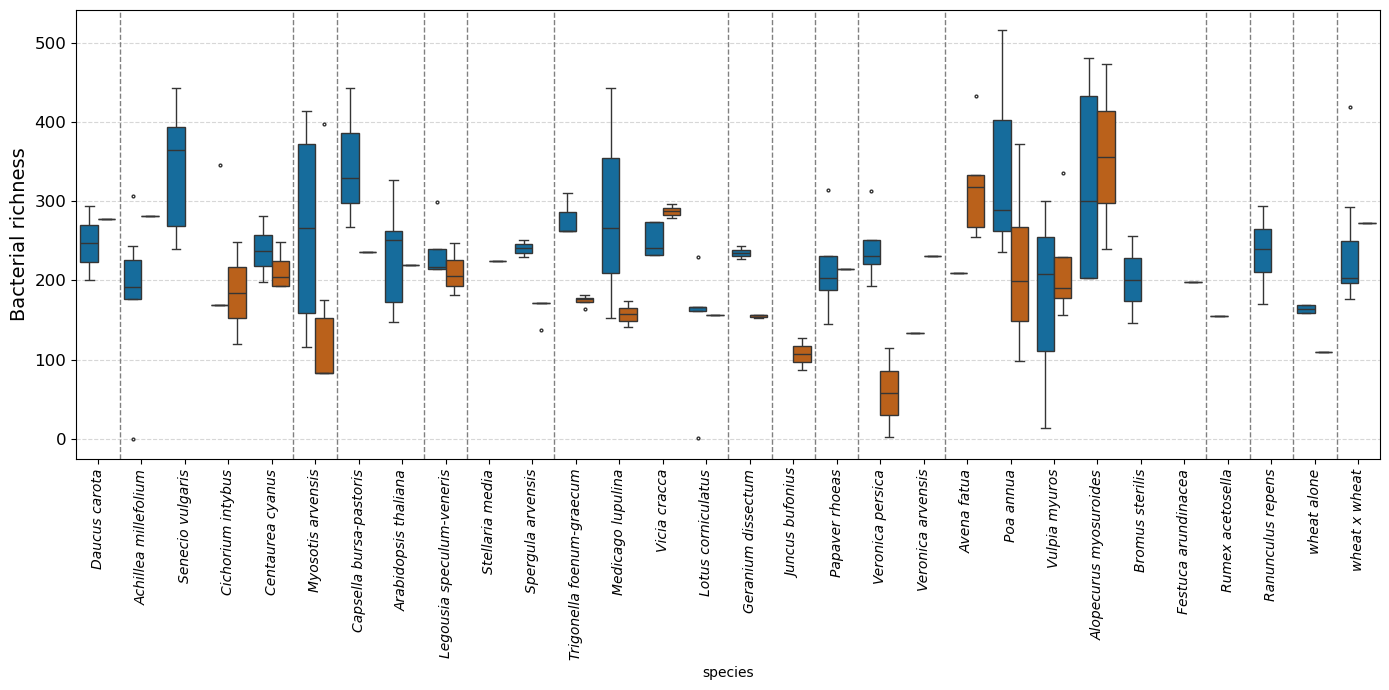

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import mannwhitneyu, ttest_ind

# --- Prepare metadata_combined as in your script ---
metadata_permissive = metadata_all[metadata_all['soil'].str.contains('permissive', case=False, na=False)]
metadata_permissive['Soil'] = 'Permissive'

metadata_resistant = metadata_all[metadata_all['soil'].str.contains('resistant', case=False, na=False)]
metadata_resistant['Soil'] = 'Resistant'

metadata_combined = pd.concat([metadata_permissive, metadata_resistant])
metadata_combined = metadata_combined.dropna(subset=['Richness_bacteria', 'species'])
metadata_combined = metadata_combined.sort_values(by=['family', 'Richness_bacteria'])

# --- Soil palette ---
soil_palette = {
    'Permissive': '#0072B2',
    'Resistant': '#D55E00'
}

# --- Compute species ordering and family boundaries ---
plant_2_family = dict(zip(metadata_combined["species"], metadata_combined["family"]))
species_sorted = metadata_combined.sort_values(by='family')['species'].unique()
species_to_family = {species: plant_2_family[species] for species in species_sorted}

family_boundaries = []
last_family = None
for idx, species in enumerate(species_sorted):
    current_family = species_to_family[species]
    if current_family != last_family:
        if last_family is not None:
            family_boundaries.append(idx)
        last_family = current_family

# --- Main plot (NO legend) ---
plt.figure(figsize=(14, 7))
ax = sns.boxplot(
    x='species', 
    y='Richness_bacteria', 
    hue='Soil', 
    data=metadata_combined, 
    palette=soil_palette,
    hue_order=['Permissive', 'Resistant'],  # <- Ensures order
    order=species_sorted,
    fliersize=2,
    linewidth=1
)

for artist in ax.artists:
    artist.set_edgecolor('black')

for x_pos in family_boundaries:
    ax.axvline(x=x_pos - 0.5, color='gray', linestyle='--', linewidth=1)

# Labels and formatting
# plt.title('Shannon Index of Bacteria by Species and Soil Type', fontsize=16)
plt.ylabel('Bacterial richness', fontsize=14)
plt.xticks(rotation=90)
ax.set_xticklabels([label.get_text() for label in ax.get_xticklabels()], fontstyle='italic', fontsize=10)
plt.yticks(fontsize=12)

# Remove the legend
ax.get_legend().remove()

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

<positron-console-cell-20>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<positron-console-cell-20>:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<positron-console-cell-20>:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


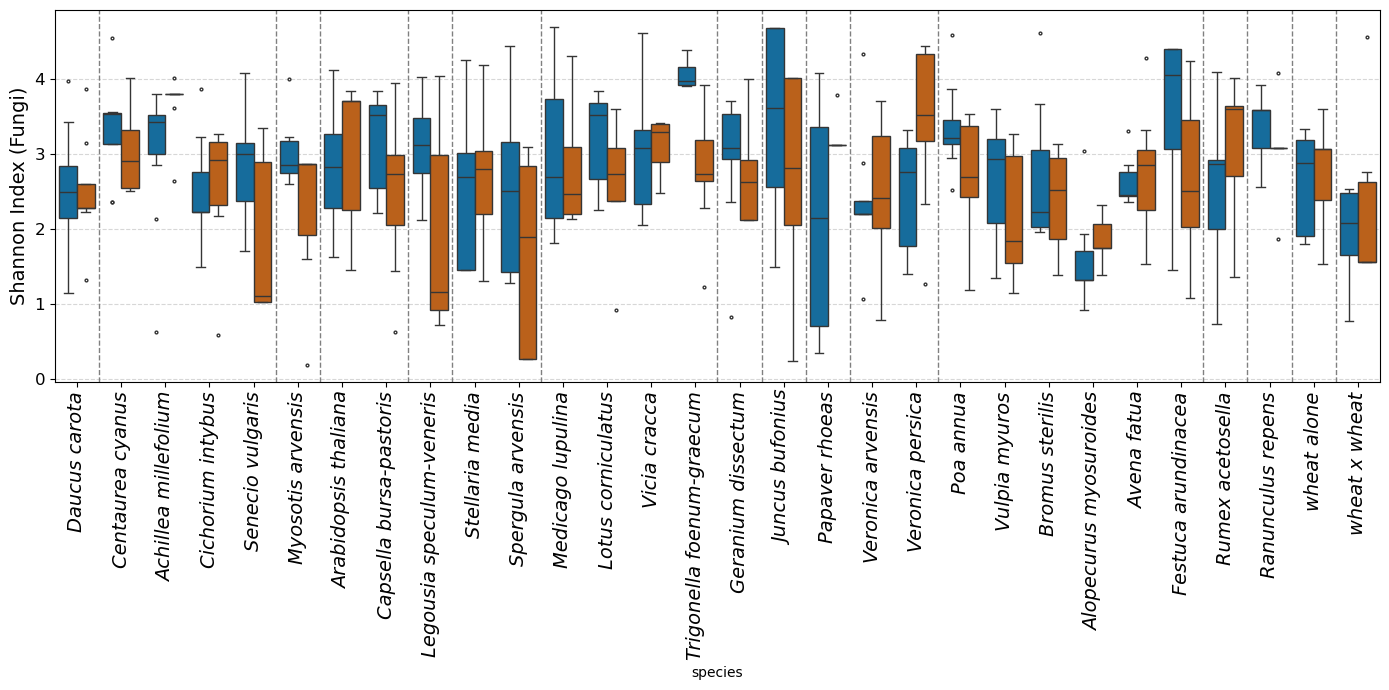

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import mannwhitneyu, ttest_ind

# --- Prepare metadata_combined as in your script ---
metadata_permissive = metadata_all[metadata_all['soil'].str.contains('permissive', case=False, na=False)]
metadata_permissive['Soil'] = 'Permissive'

metadata_resistant = metadata_all[metadata_all['soil'].str.contains('resistant', case=False, na=False)]
metadata_resistant['Soil'] = 'Resistant'

metadata_combined = pd.concat([metadata_permissive, metadata_resistant])
metadata_combined = metadata_combined.dropna(subset=['Shannon_fungi', 'species'])
metadata_combined = metadata_combined.sort_values(by=['family', 'Shannon_fungi'])

# --- Soil palette ---
# --- Soil palette ---
soil_palette = {
    'Permissive': '#0072B2',
    'Resistant': '#D55E00'
}
# --- Compute species ordering and family boundaries ---
plant_2_family = dict(zip(metadata_combined["species"], metadata_combined["family"]))
species_sorted = metadata_combined.sort_values(by='family')['species'].unique()
species_to_family = {species: plant_2_family[species] for species in species_sorted}

family_boundaries = []
last_family = None
for idx, species in enumerate(species_sorted):
    current_family = species_to_family[species]
    if current_family != last_family:
        if last_family is not None:
            family_boundaries.append(idx)
        last_family = current_family

# --- Main plot (NO legend) ---
plt.figure(figsize=(14, 7))
ax = sns.boxplot(
    x='species', 
    y='Shannon_fungi', 
    hue='Soil', 
    data=metadata_combined, 
    palette=soil_palette,
    order=species_sorted,
    fliersize=2,
    linewidth=1
)

for artist in ax.artists:
    artist.set_edgecolor('black')

for x_pos in family_boundaries:
    ax.axvline(x=x_pos - 0.5, color='gray', linestyle='--', linewidth=1)

# Labels and formatting
# plt.title('Shannon Index of fungi by Species and Soil Type', fontsize=16)
plt.ylabel('Shannon Index (Fungi)', fontsize=14)
plt.xticks(rotation=90)
ax.set_xticklabels([label.get_text() for label in ax.get_xticklabels()], fontstyle='italic', fontsize=14)
plt.yticks(fontsize=12)

# Remove the legend
ax.get_legend().remove()

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

<positron-console-cell-21>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<positron-console-cell-21>:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<positron-console-cell-21>:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


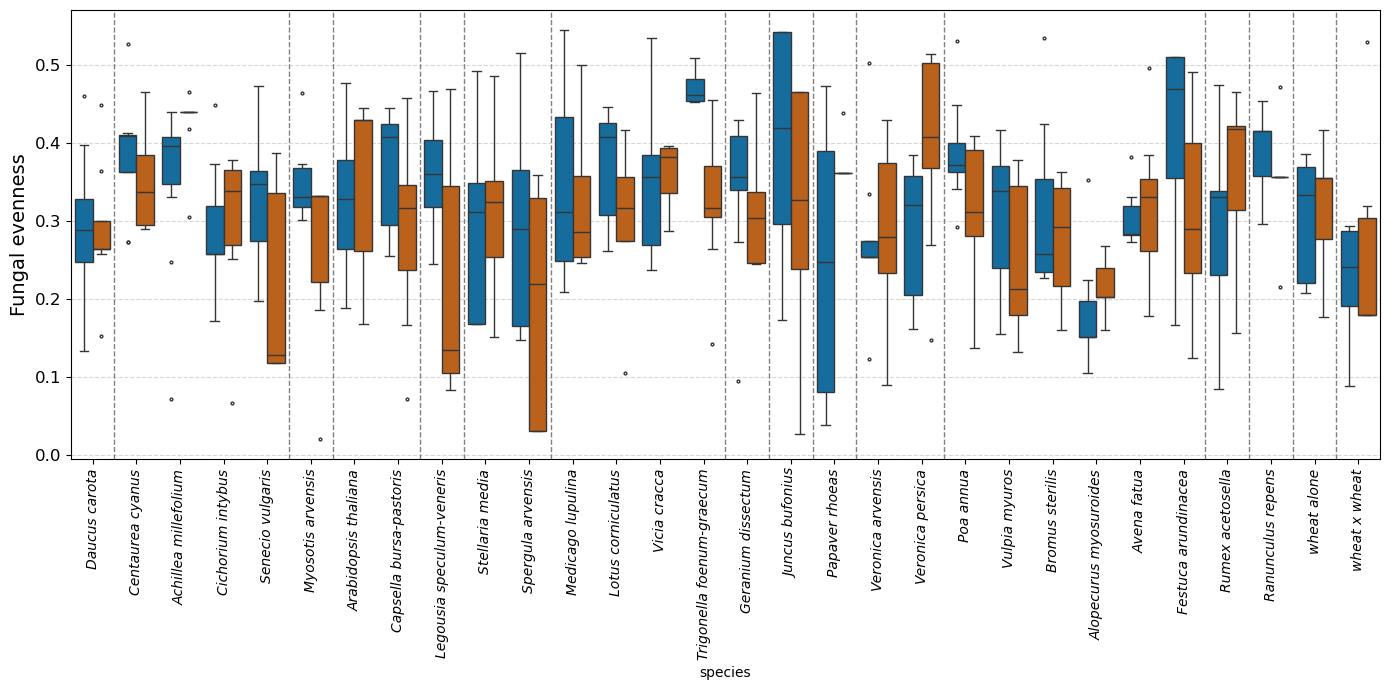

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import mannwhitneyu, ttest_ind

# --- Prepare metadata_combined as in your script ---
metadata_permissive = metadata_all[metadata_all['soil'].str.contains('permissive', case=False, na=False)]
metadata_permissive['Soil'] = 'Permissive'

metadata_resistant = metadata_all[metadata_all['soil'].str.contains('resistant', case=False, na=False)]
metadata_resistant['Soil'] = 'Resistant'

metadata_combined = pd.concat([metadata_permissive, metadata_resistant])
metadata_combined = metadata_combined.dropna(subset=['Evenness_fungi', 'species'])
metadata_combined = metadata_combined.sort_values(by=['family', 'Evenness_fungi'])

# --- Soil palette ---
soil_palette = {
    'Permissive': '#0072B2',
    'Resistant': '#D55E00'
}

# --- Compute species ordering and family boundaries ---
plant_2_family = dict(zip(metadata_combined["species"], metadata_combined["family"]))
species_sorted = metadata_combined.sort_values(by='family')['species'].unique()
species_to_family = {species: plant_2_family[species] for species in species_sorted}

family_boundaries = []
last_family = None
for idx, species in enumerate(species_sorted):
    current_family = species_to_family[species]
    if current_family != last_family:
        if last_family is not None:
            family_boundaries.append(idx)
        last_family = current_family

# --- Main plot (NO legend) ---
plt.figure(figsize=(14, 7))
ax = sns.boxplot(
    x='species', 
    y='Evenness_fungi', 
    hue='Soil', 
    data=metadata_combined, 
    palette=soil_palette,
    hue_order=['Permissive', 'Resistant'],  # <- Ensures order
    order=species_sorted,
    fliersize=2,
    linewidth=1
)

for artist in ax.artists:
    artist.set_edgecolor('black')

for x_pos in family_boundaries:
    ax.axvline(x=x_pos - 0.5, color='gray', linestyle='--', linewidth=1)

# Labels and formatting
# plt.title('Shannon Index of Bacteria by Species and Soil Type', fontsize=16)
plt.ylabel('Fungal evenness', fontsize=14)
plt.xticks(rotation=90)
ax.set_xticklabels([label.get_text() for label in ax.get_xticklabels()], fontstyle='italic', fontsize=10)
plt.yticks(fontsize=12)

# Remove the legend
ax.get_legend().remove()

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 3.2 Effects of weeds on _T. aestivum_ performance

<span style="text-decoration: underline;">Data on wheat performance:</span>

* Dry aboveground biomass (g)
* Specific Leaf Area (SLA) is a key functional trait that reflects the relationship between leaf area and dry mass.
* Height (cm)

The formula for calculating **Specific Leaf Area (SLA)** is:
<div align="center">

$$
SLA = \frac{\text{Leaf Area} \, (\text{m}^2)}{\text{Leaf Dry Mass} \, (\text{kg})}
$$

</div>

Where:
- **Leaf Area** is measured in square meters (m²).
- **Leaf Dry Mass** is measured in kilograms (kg).

## pcoa species

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from skbio.diversity import beta_diversity
from skbio.stats.ordination import pcoa
from skbio.stats.distance import permanova
from matplotlib.patches import Polygon
from scipy.spatial import ConvexHull

# ---------- CONFIG ----------
SOIL_MAP = {"Permissive": "tab:blue", "resistant": "tab:orange"}
USE_FUNCTION_TABLE = False   # False = use otu16_table, True = use abu_rel
HELLINGER = True
MIN_SAMPLES_PER_SOIL = 3
OUTDIR = "/Users/mathieuvanhove/Desktop/Work/DeepImpact/Weeds_wheat/paper_1/data/results_v4/ordination_species"
os.makedirs(OUTDIR, exist_ok=True)

# ---------- INPUTS ----------
if "sample" in metadata_all.columns:
    meta = metadata_all.set_index("sample").copy()
else:
    meta = metadata_all.copy()

if USE_FUNCTION_TABLE:
    X_full = abu_rel.copy()       # samples × functions
else:
    X_full = otu16_table.T.copy() # samples × ASVs

def run_species_pcoa(species, save=True):
    """Run ordination for one species and return PERMANOVA result if possible."""
    # 1) subset samples
    samples = meta.index[meta["species"] == species]
    samples = [s for s in samples if s in X_full.index]
    if len(samples) < 4:  # too few samples
        return None
    
    X = X_full.loc[samples].copy()

    # 2) optional Hellinger transform
    if HELLINGER:
        row_sums = X.sum(axis=1).replace(0, np.nan)
        X_rel = X.div(row_sums, axis=0).fillna(0.0)
        X_use = np.sqrt(X_rel)
    else:
        X_use = X

    # 3) distances & PCoA
    dm = beta_diversity("braycurtis", X_use.values, ids=X_use.index)
    ord_res = pcoa(dm)

    scores = ord_res.samples.loc[X_use.index, ["PC1","PC2"]].copy()
    scores["soil"] = meta.loc[scores.index, "soil"]

    # 4) plot
    fig, ax = plt.subplots(figsize=(7,6))
    for soil, sub in scores.groupby("soil"):
        c = SOIL_MAP.get(soil, "gray")
        ax.scatter(sub["PC1"], sub["PC2"], s=35, alpha=0.85, label=soil,
                   color=c, edgecolor="white", linewidth=0.6)
        # centroid
        cx, cy = sub["PC1"].mean(), sub["PC2"].mean()
        ax.scatter([cx],[cy], s=90, marker="X", color=c,
                   edgecolor="black", linewidth=0.6, zorder=3)
        # convex hull if enough points
        if len(sub) >= MIN_SAMPLES_PER_SOIL:
            try:
                pts = sub[["PC1","PC2"]].values
                hull = ConvexHull(pts)
                poly = Polygon(pts[hull.vertices], closed=True, facecolor=c,
                               alpha=0.12, edgecolor=c, linewidth=1.0)
                ax.add_patch(poly)
            except Exception:
                pass

    ax.axhline(0, color="#cccccc", lw=0.8)
    ax.axvline(0, color="#cccccc", lw=0.8)
    ax.set_xlabel(f"PC1 ({ord_res.proportion_explained['PC1']*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({ord_res.proportion_explained['PC2']*100:.1f}%)")
    ax.set_title(f"{species} — PCoA (Bray–Curtis)")
    ax.legend(frameon=False, title="Soil")
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(OUTDIR, f"{species.replace(' ', '_')}_pcoa.png"), dpi=150)
        plt.close()
    else:
        plt.show()

    # 5) PERMANOVA test
    design = meta.loc[X_use.index, ["soil"]].copy()
    if all(design["soil"].value_counts() >= MIN_SAMPLES_PER_SOIL):
        perma = permanova(distance_matrix=dm, grouping=design["soil"], permutations=999)
        return perma
    else:
        return None

# ---------- LOOP OVER SPECIES ----------
results = {}
for sp in meta["species"].unique():
    perma = run_species_pcoa(sp)
    if perma is not None:
        results[sp] = perma

# Save PERMANOVA summary
perma_df = pd.DataFrame(results).T
perma_df.to_csv(os.path.join(OUTDIR, "bacteria_permanova_results.csv"))
print("Done. Results saved in:", OUTDIR)

<positron-console-cell-6>:44: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<positron-console-cell-6>:44: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<positron-console-cell-6>:44: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<positron-console-cell-6>:44: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated 

Done. Results saved in: /Users/mathieuvanhove/Desktop/Work/DeepImpact/Weeds_wheat/paper_1/data/results_v4/ordination_species


## Dry mass


Mean and standard deviation for each soil type:
Permissive: Mean = 0.3000 g, Std Dev = 0.2178 g
resistant: Mean = 0.2812 g, Std Dev = 0.1723 g


<positron-console-cell-7>:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



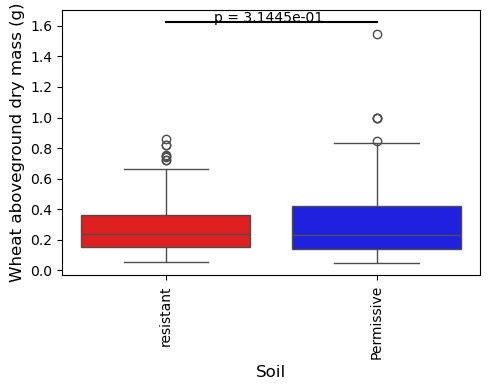

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

# Define column to plot
column_to_plot = "Dry_wheat_mass"

# Filter data
metadata_all_soil = metadata_all.dropna(subset=['soil', column_to_plot])  # Ensure no missing values

# Define custom palette for soil types
custom_palette = {"Permissive": "blue", "resistant": "red"}

# Calculate means and standard deviations for each soil type
soil_groups = metadata_all_soil.groupby('soil')[column_to_plot]
soil_stats = soil_groups.agg(['mean', 'std'])

# Print mean and standard deviation values
print("\nMean and standard deviation for each soil type:")
for soil, stats in soil_stats.iterrows():
    mean_value = stats['mean']
    std_value = stats['std']
    print(f"{soil}: Mean = {mean_value:.4f} g, Std Dev = {std_value:.4f} g")

# Perform a t-test between the two soil types
if "Permissive" in soil_groups.groups and "resistant" in soil_groups.groups:
    perm_values = soil_groups.get_group("Permissive")
    res_values = soil_groups.get_group("resistant")
    t_stat, p_value = ttest_ind(perm_values, res_values, equal_var=True)  # student t-test equal_var=True | Welch's t-test equal_var=False
else:
    p_value = None

# Create the box plot
plt.figure(figsize=(5, 4))
ax = sns.boxplot(x='soil', y=column_to_plot, data=metadata_all_soil, palette=custom_palette)

# Add p-value annotation
if p_value is not None:
    significance = ""
    if p_value < 0.001:
        significance = "***"
    elif p_value < 0.01:
        significance = "**"
    elif p_value < 0.05:
        significance = "*"

    # Annotate with p-value
    y_max = metadata_all_soil[column_to_plot].max()
    y_min = metadata_all_soil[column_to_plot].min()
    y_pos = y_max + 0.05 * (y_max - y_min)  # Position above the plot
    ax.plot([0, 1], [y_pos, y_pos], color="black", linewidth=1.5)  # Line connecting boxes
    ax.text(0.5, y_pos, f"p = {p_value:.4e} {significance}", ha="center", fontsize=10)

# Add titles and labels
plt.xlabel('Soil', fontsize=12)
plt.ylabel('Wheat aboveground dry mass (g)', fontsize=12)

# Rotate x-axis labels if needed
plt.xticks(rotation=90)

# Show the plot
plt.tight_layout()
plt.show()

## Fig. 4

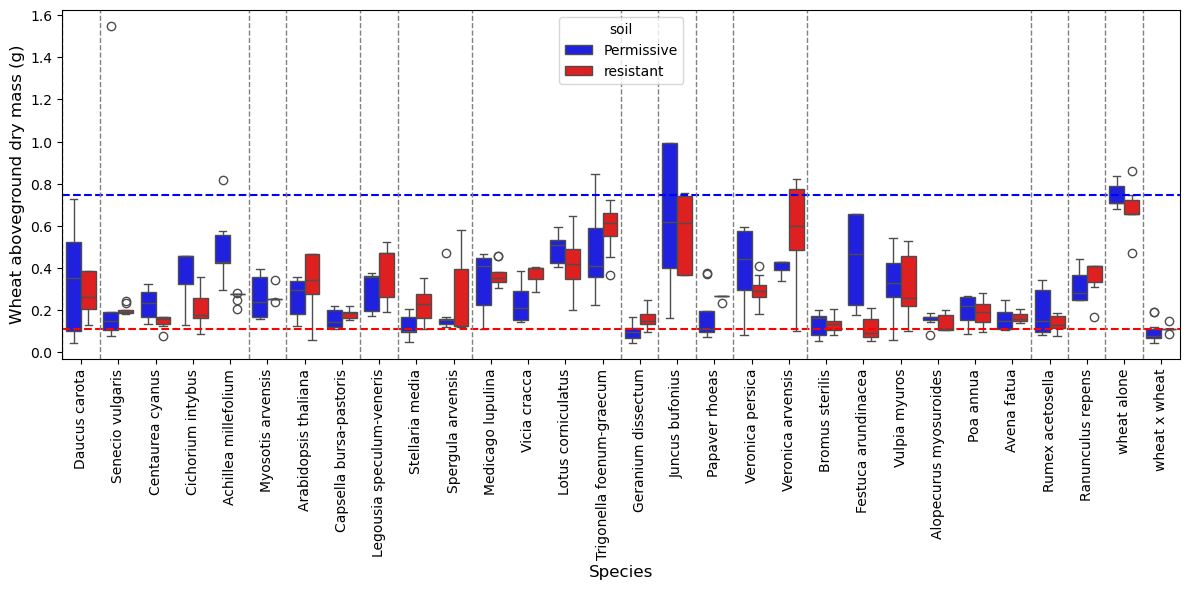

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
import pickle
column_to_plot = "Dry_wheat_mass"

with open('/Users/mathieuvanhove/Desktop/Work/DeepImpact/Weeds_wheat/paper_1/data/python/family_col_d.pkl', 'rb') as handle:
    family_col_d = pickle.load(handle)

# Filter data for the two soil types of interest
metadata_all_soil = metadata_all[metadata_all['soil'].str.contains('Permissive|resistant', case=False, na=False)]
metadata_all_soil = metadata_all_soil.sort_values(by=['family', column_to_plot])

# Assign colors based on family (used later for custom palette)
plant_2_family = dict(zip(metadata_all_soil["species"], metadata_all_soil["family"]))
col_d = {k: family_col_d.get(plant_2_family.get(k), "grey") for k in metadata_all_soil["species"].unique()}

# Define a custom palette for soil types
custom_palette = {"Permissive": "blue", "resistant": "red"}

# Create the box plot with 'species' on x-axis and 'soil' as hue
plt.figure(figsize=(12, 6))
ax = sns.boxplot(x='species', y=column_to_plot, hue='soil', data=metadata_all_soil, palette=custom_palette)

# Calculate and plot the mean of 'Dry_wheat_mass' for 'wheat alone' and 'wheat x wheat' in each soil type
mean_wheat_perm = metadata_all_soil[(metadata_all_soil['species'] == 'wheat alone') & 
                                    (metadata_all_soil['soil'].str.contains('Permissive', case=False))][column_to_plot].mean()
mean_wheat_res = metadata_all_soil[(metadata_all_soil['species'] == 'wheat x wheat') & 
                                    (metadata_all_soil['soil'].str.contains('resistant', case=False))][column_to_plot].mean()

# Add horizontal lines for the mean values of wheat alone for each soil type
ax.axhline(mean_wheat_perm, color='blue', linestyle='--', label='Mean of Wheat (Permissive)')
ax.axhline(mean_wheat_res, color='red', linestyle='--', label='Mean of Wheat (Resistant)')

# Add titles and labels
plt.xlabel('Species', fontsize=12)
plt.ylabel('Wheat aboveground dry mass (g)', fontsize=12)

# Rotate x-axis labels if they overlap
plt.xticks(rotation=90)

# Identify family boundaries for vertical lines
species_order = metadata_all_soil['species'].unique()
family_boundaries = []
last_family = None
for i, species in enumerate(species_order):
    current_family = plant_2_family[species]
    if current_family != last_family:
        family_boundaries.append(i)
        last_family = current_family

# Add vertical lines to separate families
for x in family_boundaries:
    ax.axvline(x=x - 0.5, color='gray', linestyle='--', linewidth=1)

# Add legend for horizontal lines and soil types
# plt.legend(title='Legend', bbox_to_anchor=(1.05, 1), loc='upper left')

# Finalize the plot layout
plt.tight_layout()
plt.show()

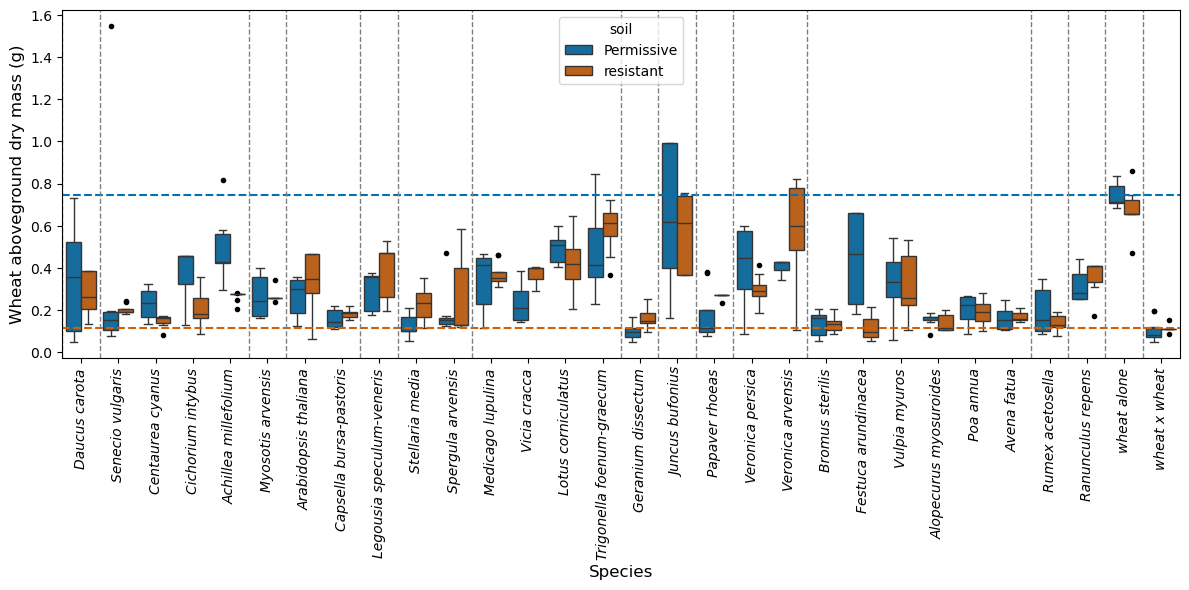

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

column_to_plot = "Dry_wheat_mass"

# Filter and sort metadata
metadata_all_soil = metadata_all[metadata_all['soil'].str.contains('Permissive|resistant', case=False, na=False)]
metadata_all_soil = metadata_all_soil.sort_values(by=['family', column_to_plot])

# Assign colors based on family
plant_2_family = dict(zip(metadata_all_soil["species"], metadata_all_soil["family"]))
col_d = {k: family_col_d.get(plant_2_family.get(k), "grey") for k in metadata_all_soil["species"].unique()}

# Colorblind-friendly soil palette (colorblind-safe: blue & orange)
custom_palette = {"Permissive": "#0072B2", "resistant": "#D55E00"}

# Create the box plot
plt.figure(figsize=(12, 6))
ax = sns.boxplot(
    x='species',
    y=column_to_plot,
    hue='soil',
    data=metadata_all_soil,
    palette=custom_palette,
    flierprops={
        'marker': 'o',
        'markerfacecolor': 'black',
        'markeredgecolor': 'black',
        'markersize': 3
    }
)

# Calculate and plot mean of 'wheat alone' and 'wheat x wheat'
mean_wheat_perm = metadata_all_soil[
    (metadata_all_soil['species'] == 'wheat alone') &
    (metadata_all_soil['soil'].str.contains('Permissive', case=False))
][column_to_plot].mean()

mean_wheat_res = metadata_all_soil[
    (metadata_all_soil['species'] == 'wheat x wheat') &
    (metadata_all_soil['soil'].str.contains('resistant', case=False))
][column_to_plot].mean()

# Horizontal lines
ax.axhline(mean_wheat_perm, color=custom_palette["Permissive"], linestyle='--', label='Mean Wheat (Permissive)')
ax.axhline(mean_wheat_res, color=custom_palette["resistant"], linestyle='--', label='Mean Wheat (Resistant)')

# Axis labels
plt.xlabel('Species', fontsize=12)
plt.ylabel('Wheat aboveground dry mass (g)', fontsize=12)

# Italic x-axis labels
plt.xticks(rotation=90, fontstyle='italic')

# Vertical dashed lines to separate plant families
species_order = metadata_all_soil['species'].unique()
family_boundaries = []
last_family = None
for i, species in enumerate(species_order):
    current_family = plant_2_family[species]
    if current_family != last_family:
        family_boundaries.append(i)
        last_family = current_family

for x in family_boundaries:
    ax.axvline(x=x - 0.5, color='gray', linestyle='--', linewidth=1)

# Finalize layout
plt.tight_layout()
plt.show()

# 3.3 Effects of weeds on the endospheric root microbiota diversity of _T. aestivum_

imported from R QMD - section 3.1.2. Differential microbial enrichment by co-cultivated weed species

## DA methods

In [12]:
mypath_res = "/Users/mathieuvanhove/Desktop/Work/DeepImpact/Weeds_wheat/paper_1/data/results_v4/"
import pandas as pd
import os

# Input files
mypath_res = "/Users/mathieuvanhove/Desktop/Work/DeepImpact/Weeds_wheat/paper_1/data/results_v4/"
file_deseq = f"{mypath_res}/DESeq2_species/DESeq_bacteria_Permissive_species_vs_wheat_x_wheat_pval.csv"
file_edger = f"{mypath_res}/edgeR_species/edgeR_bacteria_Permissive_vs_wheat_x_wheat.csv"
file_metaseq = f"{mypath_res}/metagenomeSeq_species/MetaSeq_bacteria_Permissive_CSS_wheat_x_wheat.csv"



# --- Load DESeq2 results ---
def load_and_format_deseq(file_path):
    df = pd.read_csv(file_path)
    df[['species1', 'species2']] = df['comparison'].str.split(' vs ', expand=True)
    df['species1'] = df['species1'].str.replace('.', ' ', regex=False)
    df['species2'] = df['species2'].str.replace('.', ' ', regex=False)
    df = df.drop(columns=['comparison'])
    df.columns = ['cluster', 'baseMean', 'log2FoldChange', "lfcSE", "stat", "pvalue", "padj", "taxa", "species1", "species2"]
    df["cluster"] = df["taxa"]
    return df

DESeq_permissive_all = load_and_format_deseq(file_deseq)
DESeq_permissive_df = DESeq_permissive_all[
    ((DESeq_permissive_all["species1"] == "wheat x wheat") & (DESeq_permissive_all["log2FoldChange"] < -2) & (DESeq_permissive_all["pvalue"] < 0.05)) |
    ((DESeq_permissive_all["species2"] == "wheat x wheat") & (DESeq_permissive_all["log2FoldChange"] > 2) & (DESeq_permissive_all["pvalue"] < 0.05))
]

# --- Load edgeR results ---
def load_edgeR_results(filepath):
    df = pd.read_csv(filepath)
    df[['species1', 'species2']] = df['comparison'].str.split(' vs ', expand=True)
    df['species1'] = df['species1'].str.replace('.', ' ', regex=False)
    df['species2'] = df['species2'].str.replace('.', ' ', regex=False)
    df['cluster'] = df['taxa']
    return df

edgeR_permissive_all = load_edgeR_results(file_edger)
edgeR_permissive_df = edgeR_permissive_all[
    ((edgeR_permissive_all["species1"] == "wheat x wheat") & (edgeR_permissive_all["logFC"] < -2) & (edgeR_permissive_all["PValue"] < 0.01)) |
    ((edgeR_permissive_all["species2"] == "wheat x wheat") & (edgeR_permissive_all["logFC"] > 2) & (edgeR_permissive_all["PValue"] < 0.01))
]

# --- Load metagenomeSeq results ---
def load_metaseq_results(filepath):
    df = pd.read_csv(filepath)
    df[['species', 'cluster']] = df['Unnamed: 0'].str.split('.Cluster_', expand=True)
    df['cluster'] = 'Cluster_' + df['cluster']
    df['species'] = df['species'].str.strip()
    if 'logFC' not in df.columns:
        df.rename(columns={df.columns[1]: 'logFC'}, inplace=True)
    return df

metaseq_permissive_all = load_metaseq_results(file_metaseq)
metaseq_permissive_df = metaseq_permissive_all[
    metaseq_permissive_all['adjPvalues'] < 0.05
]

# --- Build species list ---
species_list = sorted(
    set(edgeR_permissive_df['species1']) | set(edgeR_permissive_df['species2']) |
    set(DESeq_permissive_df['species1']) | set(DESeq_permissive_df['species2']) |
    set(metaseq_permissive_df['species'])
)
species_list = [sp for sp in species_list if sp != "wheat x wheat"]

# --- Store results ---
species_cluster_counts = {}
clusters_by_method = {}

for species in species_list:
    # edgeR clusters
    clusters_edgeR = set(edgeR_permissive_df.loc[
        ((edgeR_permissive_df['species1'] == species) & (edgeR_permissive_df['logFC'] > 2)) |
        ((edgeR_permissive_df['species2'] == species) & (edgeR_permissive_df['logFC'] < -2)),
        'cluster'
    ])

    # DESeq2 clusters
    clusters_DESeq = set(DESeq_permissive_df.loc[
        ((DESeq_permissive_df['species1'] == species) & (DESeq_permissive_df['log2FoldChange'] > 2)) |
        ((DESeq_permissive_df['species2'] == species) & (DESeq_permissive_df['log2FoldChange'] < -2)),
        'cluster'
    ])

    # metagenomeSeq clusters
    clusters_Mseq = set(metaseq_permissive_df.loc[
        (metaseq_permissive_df['species'] == species) & (metaseq_permissive_df['logFC'] > 2),
        'cluster'
    ])

    # Save for later
    clusters_by_method[species] = {
        'DESeq': clusters_DESeq,
        'edgeR': clusters_edgeR,
        'Mseq': clusters_Mseq
    }

    all_clusters = clusters_edgeR | clusters_DESeq | clusters_Mseq
    cluster_counts = {
        cluster: sum([
            cluster in clusters_edgeR,
            cluster in clusters_DESeq,
            cluster in clusters_Mseq
        ])
        for cluster in all_clusters
    }

    species_cluster_counts[species] = pd.DataFrame.from_dict(
        cluster_counts, orient='index', columns=['Presence Count'])
    species_cluster_counts[species].index.name = 'Cluster'

# --- Create summary table ---
summary_data = []
unique_clusters_per_species = {}

for species, df in species_cluster_counts.items():
    clusters_DESeq = clusters_by_method[species]['DESeq']
    clusters_edgeR = clusters_by_method[species]['edgeR']
    clusters_Mseq = clusters_by_method[species]['Mseq']

    # Combinations
    all_3 = clusters_edgeR & clusters_DESeq & clusters_Mseq
    DESeq_Mseq = (clusters_DESeq & clusters_Mseq) - clusters_edgeR
    edgeR_DESeq = (clusters_edgeR & clusters_DESeq) - clusters_Mseq
    edgeR_Mseq = (clusters_edgeR & clusters_Mseq) - clusters_DESeq
    edgeR_only = clusters_edgeR - clusters_DESeq - clusters_Mseq
    DESeq_only = clusters_DESeq - clusters_edgeR - clusters_Mseq
    Mseq_only = clusters_Mseq - clusters_edgeR - clusters_DESeq

    # Save cluster sets
    unique_clusters_per_species[species] = {
        "(edgeR + DESeq + Mseq)": all_3,
        "(DESeq + Mseq)": DESeq_Mseq,
        "(edgeR + DESeq)": edgeR_DESeq,
        "(edgeR + Mseq)": edgeR_Mseq,
        "(edgeR only)": edgeR_only,
        "(DESeq only)": DESeq_only,
        "(Mseq only)": Mseq_only
    }

    # Fill summary
    summary_data.append({
        "Species": species,
        "(edgeR + DESeq + Mseq)": len(all_3),
        "(DESeq + Mseq)": len(DESeq_Mseq),
        "(edgeR + DESeq)": len(edgeR_DESeq),
        "(edgeR + Mseq)": len(edgeR_Mseq),
        "(edgeR only)": len(edgeR_only),
        "(DESeq only)": len(DESeq_only),
        "(Mseq only)": len(Mseq_only)
    })

summary_df = pd.DataFrame(summary_data)

# --- Add Total Unique Clusters per species ---
summary_df["Total_Unique_Clusters"] = [
    len(set().union(*unique_clusters_per_species[species].values()))
    for species in summary_df["Species"]
]

print(summary_df)

# --- Save the summary ---
output_file = os.path.join(mypath_res, "differential_abundance", "method_overlap_bacteria_permissive_v3.csv")
os.makedirs(os.path.dirname(output_file), exist_ok=True)
summary_df.to_csv(output_file, index=False)

print(f"Saved to: {output_file}")

# --- Calculate total unique clusters per method (across all species) ---
method_totals = {}

for method in ["(edgeR + DESeq + Mseq)", "(DESeq + Mseq)", "(edgeR + DESeq)", "(edgeR + Mseq)", "(edgeR only)", "(DESeq only)", "(Mseq only)"]:
    clusters = set()
    for species in unique_clusters_per_species:
        clusters.update(unique_clusters_per_species[species][method])
    method_totals[method] = len(clusters)

print("\nTotal unique clusters per method:")
print(method_totals)

                      Species  (edgeR + DESeq + Mseq)  (DESeq + Mseq)  \
0        Achillea millefolium                       0              18   
1      Alopecurus myosuroides                       0               4   
2        Arabidopsis thaliana                       0               7   
3                 Avena fatua                       0               4   
4             Bromus sterilis                       0               1   
5     Capsella bursa-pastoris                       0               6   
6            Centaurea cyanus                       0               5   
7           Cichorium intybus                       0               6   
8               Daucus carota                       0               1   
9              Festuca myuros                       0               4   
10         Geranium dissectum                       0               4   
11            Juncus bufonius                       0               5   
12  Legousia speculum-veneris                      

In [13]:
import pandas as pd
import os

# Input files
file_deseq = f"{mypath_res}/DESeq2_species/DESeq_bacteria_resistant_species_vs_wheat_x_wheat_pval.csv"
file_edger = f"{mypath_res}/edgeR_species/edgeR_bacteria_resistant_vs_wheat_x_wheat.csv"
file_metaseq = f"{mypath_res}/metagenomeSeq_species/MetaSeq_bacteria_Resistant_CSS_wheat_x_wheat.csv"

# --- Load DESeq2 results ---
def load_and_format_deseq(file_path):
    df = pd.read_csv(file_path)
    df[['species1', 'species2']] = df['comparison'].str.split(' vs ', expand=True)
    df['species1'] = df['species1'].str.replace('.', ' ', regex=False)
    df['species2'] = df['species2'].str.replace('.', ' ', regex=False)
    df = df.drop(columns=['comparison'])
    df.columns = ['cluster', 'baseMean', 'log2FoldChange', "lfcSE", "stat", "pvalue", "padj", "taxa", "species1", "species2"]
    df["cluster"] = df["taxa"]
    return df

DESeq_resistant_all = load_and_format_deseq(file_deseq)
DESeq_resistant_df = DESeq_resistant_all[
    ((DESeq_resistant_all["species1"] == "wheat x wheat") & (DESeq_resistant_all["log2FoldChange"] < -2) & (DESeq_resistant_all["pvalue"] < 0.05)) |
    ((DESeq_resistant_all["species2"] == "wheat x wheat") & (DESeq_resistant_all["log2FoldChange"] > 2) & (DESeq_resistant_all["pvalue"] < 0.05))
]

# --- Load edgeR results ---
def load_edgeR_results(filepath):
    df = pd.read_csv(filepath)
    df[['species1', 'species2']] = df['comparison'].str.split(' vs ', expand=True)
    df['species1'] = df['species1'].str.replace('.', ' ', regex=False)
    df['species2'] = df['species2'].str.replace('.', ' ', regex=False)
    df['cluster'] = df['taxa']
    return df

edgeR_resistant_all = load_edgeR_results(file_edger)
edgeR_resistant_df = edgeR_resistant_all[
    ((edgeR_resistant_all["species1"] == "wheat x wheat") & (edgeR_resistant_all["logFC"] < -2) & (edgeR_resistant_all["PValue"] < 0.01)) |
    ((edgeR_resistant_all["species2"] == "wheat x wheat") & (edgeR_resistant_all["logFC"] > 2) & (edgeR_resistant_all["PValue"] < 0.01))
]

# --- Load metagenomeSeq results ---
def load_metaseq_results(filepath):
    df = pd.read_csv(filepath)
    df[['species', 'cluster']] = df['Unnamed: 0'].str.split('.Cluster_', expand=True)
    df['cluster'] = 'Cluster_' + df['cluster']
    df['species'] = df['species'].str.strip()
    if 'logFC' not in df.columns:
        df.rename(columns={df.columns[1]: 'logFC'}, inplace=True)
    return df

metaseq_resistant_all = load_metaseq_results(file_metaseq)
metaseq_resistant_df = metaseq_resistant_all[
    metaseq_resistant_all['adjPvalues'] < 0.05
]

# --- Build species list ---
species_list = sorted(
    set(edgeR_resistant_df['species1']) | set(edgeR_resistant_df['species2']) |
    set(DESeq_resistant_df['species1']) | set(DESeq_resistant_df['species2']) |
    set(metaseq_resistant_df['species'])
)
species_list = [sp for sp in species_list if sp != "wheat x wheat"]

# --- Store results ---
species_cluster_counts = {}
clusters_by_method = {}

for species in species_list:
    # edgeR clusters
    clusters_edgeR = set(edgeR_resistant_df.loc[
        ((edgeR_resistant_df['species1'] == species) & (edgeR_resistant_df['logFC'] > 2)) |
        ((edgeR_resistant_df['species2'] == species) & (edgeR_resistant_df['logFC'] < -2)),
        'cluster'
    ])

    # DESeq2 clusters
    clusters_DESeq = set(DESeq_resistant_df.loc[
        ((DESeq_resistant_df['species1'] == species) & (DESeq_resistant_df['log2FoldChange'] > 2)) |
        ((DESeq_resistant_df['species2'] == species) & (DESeq_resistant_df['log2FoldChange'] < -2)),
        'cluster'
    ])

    # metagenomeSeq clusters
    clusters_Mseq = set(metaseq_resistant_df.loc[
        (metaseq_resistant_df['species'] == species) & (metaseq_resistant_df['logFC'] > 2),
        'cluster'
    ])

    # Save for later
    clusters_by_method[species] = {
        'DESeq': clusters_DESeq,
        'edgeR': clusters_edgeR,
        'Mseq': clusters_Mseq
    }

    all_clusters = clusters_edgeR | clusters_DESeq | clusters_Mseq
    cluster_counts = {
        cluster: sum([
            cluster in clusters_edgeR,
            cluster in clusters_DESeq,
            cluster in clusters_Mseq
        ])
        for cluster in all_clusters
    }

    species_cluster_counts[species] = pd.DataFrame.from_dict(
        cluster_counts, orient='index', columns=['Presence Count'])
    species_cluster_counts[species].index.name = 'Cluster'

# --- Create summary table ---
summary_data = []
unique_clusters_per_species = {}

for species, df in species_cluster_counts.items():
    clusters_DESeq = clusters_by_method[species]['DESeq']
    clusters_edgeR = clusters_by_method[species]['edgeR']
    clusters_Mseq = clusters_by_method[species]['Mseq']

    # Combinations
    all_3 = clusters_edgeR & clusters_DESeq & clusters_Mseq
    DESeq_Mseq = (clusters_DESeq & clusters_Mseq) - clusters_edgeR
    edgeR_DESeq = (clusters_edgeR & clusters_DESeq) - clusters_Mseq
    edgeR_Mseq = (clusters_edgeR & clusters_Mseq) - clusters_DESeq
    edgeR_only = clusters_edgeR - clusters_DESeq - clusters_Mseq
    DESeq_only = clusters_DESeq - clusters_edgeR - clusters_Mseq
    Mseq_only = clusters_Mseq - clusters_edgeR - clusters_DESeq

    # Save cluster sets for later
    unique_clusters_per_species[species] = {
        "(edgeR + DESeq + Mseq)": all_3,
        "(DESeq + Mseq)": DESeq_Mseq,
        "(edgeR + DESeq)": edgeR_DESeq,
        "(edgeR + Mseq)": edgeR_Mseq,
        "(edgeR only)": edgeR_only,
        "(DESeq only)": DESeq_only,
        "(Mseq only)": Mseq_only
    }

    # Fill summary data
    summary_data.append({
        "Species": species,
        "(edgeR + DESeq + Mseq)": len(all_3),
        "(DESeq + Mseq)": len(DESeq_Mseq),
        "(edgeR + DESeq)": len(edgeR_DESeq),
        "(edgeR + Mseq)": len(edgeR_Mseq),
        "(edgeR only)": len(edgeR_only),
        "(DESeq only)": len(DESeq_only),
        "(Mseq only)": len(Mseq_only)
    })

summary_df = pd.DataFrame(summary_data)

# --- Add Total Unique Clusters per species ---
summary_df["Total_Unique_Clusters"] = [
    len(set().union(*unique_clusters_per_species[species].values()))
    for species in summary_df["Species"]
]

print(summary_df)

# --- Save the summary ---
output_file = os.path.join(mypath_res, "differential_abundance", "method_overlap_bacteria_resistant_v3.csv")
os.makedirs(os.path.dirname(output_file), exist_ok=True)
summary_df.to_csv(output_file, index=False)

print(f"Saved to: {output_file}")

# --- Calculate total unique clusters per method (across all species) ---
method_totals = {}

for method in ["(edgeR + DESeq + Mseq)", "(DESeq + Mseq)", "(edgeR + DESeq)", "(edgeR + Mseq)", "(edgeR only)", "(DESeq only)", "(Mseq only)"]:
    clusters = set()
    for species in unique_clusters_per_species:
        clusters.update(unique_clusters_per_species[species][method])
    method_totals[method] = len(clusters)

print("\nTotal unique clusters per method:")
print(method_totals)

                      Species  (edgeR + DESeq + Mseq)  (DESeq + Mseq)  \
0        Achillea millefolium                       0              21   
1      Alopecurus myosuroides                       0               4   
2        Arabidopsis thaliana                       0              10   
3                 Avena fatua                       0              11   
4             Bromus sterilis                       0               9   
5     Capsella bursa-pastoris                       0               7   
6            Centaurea cyanus                       0               3   
7           Cichorium intybus                       0               7   
8               Daucus carota                       0               6   
9              Festuca myuros                       0               4   
10         Geranium dissectum                       0               6   
11            Juncus bufonius                       0              12   
12  Legousia speculum-veneris                      

In [15]:
import pandas as pd
import numpy as np
import os
from collections import defaultdict

# Define the path to your data

# Load metadata to get plant families
# metadata_all_ = mypath + 'metadata_final_bacteria.txt'
# metadata_all = pd.read_csv(metadata_all_, sep=',')

# Create a dictionary to map species to families
# plant_2_family = dict(zip(metadata_all["species"], metadata_all["family"]))

# Load DESeq2, edgeR, and metagenomeSeq results
file_deseq_permissive = f"{mypath_res}/DESeq2_species/DESeq_bacteria_Permissive_species_vs_wheat_x_wheat_pval.csv"
file_edger_permissive = f"{mypath_res}/edgeR_species/edgeR_bacteria_Permissive_vs_wheat_x_wheat.csv"
file_metaseq_permissive = f"{mypath_res}/metagenomeSeq_species/MetaSeq_bacteria_Permissive_CSS_wheat_x_wheat.csv"

# Resistant soil
file_deseq_resistant = f"{mypath_res}/DESeq2_species/DESeq_bacteria_Resistant_species_vs_wheat_x_wheat_pval.csv"
file_edger_resistant = f"{mypath_res}/edgeR_species/edgeR_bacteria_Resistant_vs_wheat_x_wheat.csv"
file_metaseq_resistant = f"{mypath_res}/metagenomeSeq_species/MetaSeq_bacteria_Resistant_CSS_wheat_x_wheat.csv"

# Define functions to load and process data
def load_and_format_deseq(file_path):
    df = pd.read_csv(file_path)
    df[['species1', 'species2']] = df['comparison'].str.split(' vs ', expand=True)
    df['species1'] = df['species1'].str.replace('.', ' ', regex=False)
    df['species2'] = df['species2'].str.replace('.', ' ', regex=False)
    df = df.drop(columns=['comparison'])
    df.columns = ['cluster', 'baseMean', 'log2FoldChange', "lfcSE", "stat", "pvalue", "padj", "taxa", "species1", "species2"]
    df["cluster"] = df["taxa"]
    return df

def load_edgeR_results(filepath):
    df = pd.read_csv(filepath)
    df[['species1', 'species2']] = df['comparison'].str.split(' vs ', expand=True)
    df['species1'] = df['species1'].str.replace('.', ' ', regex=False)
    df['species2'] = df['species2'].str.replace('.', ' ', regex=False)
    df['cluster'] = df['taxa']
    return df

def load_metaseq_results(filepath):
    df = pd.read_csv(filepath)
    df[['species', 'cluster']] = df['Unnamed: 0'].str.split('.Cluster_', expand=True)
    df['cluster'] = 'Cluster_' + df['cluster']
    df['species'] = df['species'].str.strip()
    if 'logFC' not in df.columns:
        df.rename(columns={df.columns[1]: 'logFC'}, inplace=True)
    return df

# Load data
# Permissive soil
DESeq_permissive_all = load_and_format_deseq(file_deseq_permissive)
DESeq_permissive_df = DESeq_permissive_all[
    ((DESeq_permissive_all["species1"] == "wheat x wheat") & (DESeq_permissive_all["log2FoldChange"] < -2) & (DESeq_permissive_all["pvalue"] < 0.05)) |
    ((DESeq_permissive_all["species2"] == "wheat x wheat") & (DESeq_permissive_all["log2FoldChange"] > 2) & (DESeq_permissive_all["pvalue"] < 0.05))
]

edgeR_permissive_all = load_edgeR_results(file_edger_permissive)
edgeR_permissive_df = edgeR_permissive_all[
    ((edgeR_permissive_all["species1"] == "wheat x wheat") & (edgeR_permissive_all["logFC"] < -2) & (edgeR_permissive_all["PValue"] < 0.01)) |
    ((edgeR_permissive_all["species2"] == "wheat x wheat") & (edgeR_permissive_all["logFC"] > 2) & (edgeR_permissive_all["PValue"] < 0.01))
]

metaseq_permissive_all = load_metaseq_results(file_metaseq_permissive)
metaseq_permissive_df = metaseq_permissive_all[metaseq_permissive_all['adjPvalues'] < 0.05]

# Resistant soil
DESeq_resistant_all = load_and_format_deseq(file_deseq_resistant)
DESeq_resistant_df = DESeq_resistant_all[
    ((DESeq_resistant_all["species1"] == "wheat x wheat") & (DESeq_resistant_all["log2FoldChange"] < -2) & (DESeq_resistant_all["pvalue"] < 0.05)) |
    ((DESeq_resistant_all["species2"] == "wheat x wheat") & (DESeq_resistant_all["log2FoldChange"] > 2) & (DESeq_resistant_all["pvalue"] < 0.05))
]

edgeR_resistant_all = load_edgeR_results(file_edger_resistant)
edgeR_resistant_df = edgeR_resistant_all[
    ((edgeR_resistant_all["species1"] == "wheat x wheat") & (edgeR_resistant_all["logFC"] < -2) & (edgeR_resistant_all["PValue"] < 0.01)) |
    ((edgeR_resistant_all["species2"] == "wheat x wheat") & (edgeR_resistant_all["logFC"] > 2) & (edgeR_resistant_all["PValue"] < 0.01))
]

metaseq_resistant_all = load_metaseq_results(file_metaseq_resistant)
metaseq_resistant_df = metaseq_resistant_all[metaseq_resistant_all['adjPvalues'] < 0.05]

# Create output directory
output_dir = os.path.join(mypath_res, "figures")
os.makedirs(output_dir, exist_ok=True)

# Function to extract phylum from taxa string
def extract_phylum(taxa_string):
    if ';' in taxa_string:
        taxa_parts = taxa_string.split(';')
        if len(taxa_parts) >= 2:
            return taxa_parts[1]  # Phylum should be the second element
    return "unidentified"

# Function to extract genus from taxa string
def extract_genus(taxa_string):
    if ';' in taxa_string:
        taxa_parts = taxa_string.split(';')
        if len(taxa_parts) >= 6:  # Assuming Kingdom;Phylum;Class;Order;Family;Genus
            return taxa_parts[5]
        elif len(taxa_parts) > 0:
            return taxa_parts[-1]  # Return last available level
    return taxa_string

# Function to standardize data extraction for each method
def process_method_data(method_df, method_name, soil_type):
    result_data = []
    
    if method_name in ['DESeq2', 'edgeR']:
        for _, row in method_df.iterrows():
            species = None
            fold_change = 0
            
            if row['species1'] != "wheat x wheat" and (
                (method_name == 'DESeq2' and row['log2FoldChange'] > 0) or
                (method_name == 'edgeR' and row['logFC'] > 0)
            ):
                species = row['species1']
                fold_change = row['log2FoldChange'] if method_name == 'DESeq2' else row['logFC']
            elif row['species2'] != "wheat x wheat" and (
                (method_name == 'DESeq2' and row['log2FoldChange'] < 0) or
                (method_name == 'edgeR' and row['logFC'] < 0)
            ):
                species = row['species2']
                fold_change = -row['log2FoldChange'] if method_name == 'DESeq2' else -row['logFC']
            
            if species and species in plant_2_family:
                result_data.append({
                    'Cluster': row['cluster'],
                    'Taxa': row['taxa'],
                    'Phylum': extract_phylum(row['taxa']),
                    'Genus': extract_genus(row['taxa']),
                    'Plant_Species': species,
                    'Plant_Family': plant_2_family[species],
                    'Method': method_name,
                    'Soil': soil_type,
                    'log2FC': fold_change
                })
    else:  # metagenomeSeq
        for _, row in method_df.iterrows():
            species = row['species']
            if species != "wheat x wheat" and row['logFC'] > 0 and species in plant_2_family:
                # Handle potential differences in metagenomeSeq data structure
                taxa = row.get('taxa', row['cluster'])
                
                result_data.append({
                    'Cluster': row['cluster'],
                    'Taxa': taxa,
                    'Phylum': extract_phylum(taxa) if ';' in taxa else "unidentified",
                    'Genus': extract_genus(taxa),
                    'Plant_Species': species,
                    'Plant_Family': plant_2_family[species],
                    'Method': method_name,
                    'Soil': soil_type,
                    'log2FC': row['logFC']
                })
                
    return result_data

# Collect data from all methods for both soil types
all_data = []

# Resistant soil
all_data.extend(process_method_data(DESeq_resistant_df, 'DESeq2', 'Resistant'))
all_data.extend(process_method_data(edgeR_resistant_df, 'edgeR', 'Resistant'))
all_data.extend(process_method_data(metaseq_resistant_df, 'metagenomeSeq', 'Resistant'))

# Permissive soil
all_data.extend(process_method_data(DESeq_permissive_df, 'DESeq2', 'Permissive'))
all_data.extend(process_method_data(edgeR_permissive_df, 'edgeR', 'Permissive'))
all_data.extend(process_method_data(metaseq_permissive_df, 'metagenomeSeq', 'Permissive'))

# Convert to DataFrame
all_data_df = pd.DataFrame(all_data)

# Identify multi-method clusters
# Group by cluster and count distinct methods
cluster_method_counts = all_data_df.groupby(['Cluster', 'Soil'])['Method'].nunique().reset_index()
multi_method_clusters = cluster_method_counts[cluster_method_counts['Method'] >= 2]

# Filter for only multi-method clusters
multi_method_data = all_data_df[all_data_df['Cluster'].isin(multi_method_clusters['Cluster'])]

# For each multi-method cluster, create an aggregated record
aggregated_records = []

for (cluster, soil), group in multi_method_data.groupby(['Cluster', 'Soil']):
    # Extract unique values
    taxa = group['Taxa'].iloc[0]  # Taxa should be the same for all methods for a given cluster
    phylum = cluster_2_phylum_d.get(taxa)  # Phylum should be the same for all methods
    genus = cluster_2_genus_d.get(taxa)  # Genus should be the same for all methods
    
    # Get list of methods that detected this cluster
    methods = sorted(group['Method'].unique())
    methods_str = ", ".join(methods)
    
    # Get unique plant species
    plant_species = sorted(group['Plant_Species'].unique())
    plant_species_str = ", ".join(plant_species)
    
    # Get unique plant families
    plant_families = sorted(group['Plant_Family'].unique())
    plant_families_str = ", ".join(plant_families)
    
    # Calculate average log2FC across all methods
    avg_log2fc = group['log2FC'].mean()
    
    # Create the aggregated record
    aggregated_records.append({
        'Cluster': cluster,
        'Taxa': taxa,
        'Phylum': phylum,
        'Genus': genus,
        'Soil': soil,
        'Methods': methods_str,
        'Method_Count': len(methods),
        'Plant_Species': plant_species_str,
        'Plant_Families': plant_families_str,
        'Plant_Species_Count': len(plant_species),
        'Average_log2FC': avg_log2fc
    })

# Convert to DataFrame
aggregated_df = pd.DataFrame(aggregated_records)

# Sort by soil, method count, and then phylum
aggregated_df = aggregated_df.sort_values(['Soil', 'Method_Count', 'Phylum', 'Average_log2FC'], 
                                        ascending=[True, False, True, False])

# Save to CSV
output_file = os.path.join(output_dir, "multi_method_taxa_table.csv")
aggregated_df.to_csv(output_file, index=False)

# Print summary statistics
print(f"Total multi-method taxa: {len(aggregated_df)}")
print(f"Resistant soil: {len(aggregated_df[aggregated_df['Soil'] == 'Resistant'])}")
print(f"Permissive soil: {len(aggregated_df[aggregated_df['Soil'] == 'Permissive'])}")

# Method combination counts
print("\nMethod combinations:")
method_counts = aggregated_df.groupby(['Soil', 'Methods']).size().reset_index(name='Count')
for _, row in method_counts.iterrows():
    print(f"{row['Soil']} soil - {row['Methods']}: {row['Count']} taxa")

# Phylum distribution
print("\nPhylum distribution:")
phylum_counts = aggregated_df.groupby(['Soil', 'Phylum']).size().reset_index(name='Count')
for _, row in phylum_counts.iterrows():
    print(f"{row['Soil']} soil - {row['Phylum']}: {row['Count']} taxa")

# Create an HTML table for better visualization
def generate_html_table(df):
    # Define CSS styles
    styles = """
    <style>
    table {
        border-collapse: collapse;
        width: 100%;
        font-family: Arial, sans-serif;
    }
    th, td {
        text-align: left;
        padding: 8px;
        border: 1px solid #ddd;
    }
    th {
        background-color: #4CAF50;
        color: white;
    }
    tr:nth-child(even) {
        background-color: #f2f2f2;
    }
    tr:hover {
        background-color: #ddd;
    }
    .resistant {
        background-color: #ffebee;
    }
    .permissive {
        background-color: #e3f2fd;
    }
    </style>
    """
    
    # Start HTML
    html = f"""
    <!DOCTYPE html>
    <html>
    <head>
    <title>Multi-Method Bacterial Taxa</title>
    {styles}
    </head>
    <body>
    <h1>Multi-Method Bacterial Taxa</h1>
    <table>
    <tr>
        <th>Cluster</th>
        <th>Genus</th>
        <th>Phylum</th>
        <th>Soil</th>
        <th>Methods</th>
        <th>Plant Species</th>
        <th>Plant Families</th>
        <th>Avg log2FC</th>
    </tr>
    """
    
    # Add rows
    for _, row in df.iterrows():
        soil_class = "resistant" if row['Soil'] == 'Resistant' else "permissive"
        html += f"""
        <tr class="{soil_class}">
            <td>{row['Cluster']}</td>
            <td>{row['Genus']}</td>
            <td>{row['Phylum']}</td>
            <td>{row['Soil']}</td>
            <td>{row['Methods']}</td>
            <td>{row['Plant_Species']}</td>
            <td>{row['Plant_Families']}</td>
            <td>{row['Average_log2FC']:.2f}</td>
        </tr>
        """
    
    # Close HTML
    html += """
    </table>
    </body>
    </html>
    """
    
    return html

# Generate and save HTML table
html_table = generate_html_table(aggregated_df)
html_output_file = os.path.join(output_dir, "multi_method_taxa_table.html")
with open(html_output_file, 'w') as f:
    f.write(html_table)

print(f"\nTable saved to CSV: {output_file}")
print(f"HTML table saved to: {html_output_file}")

Total multi-method taxa: 98
Resistant soil: 55
Permissive soil: 43

Method combinations:
Permissive soil - DESeq2: 8 taxa
Permissive soil - DESeq2, metagenomeSeq: 25 taxa
Permissive soil - metagenomeSeq: 10 taxa
Resistant soil - DESeq2: 3 taxa
Resistant soil - DESeq2, edgeR: 6 taxa
Resistant soil - DESeq2, metagenomeSeq: 28 taxa
Resistant soil - edgeR: 3 taxa
Resistant soil - edgeR, metagenomeSeq: 12 taxa
Resistant soil - metagenomeSeq: 3 taxa

Phylum distribution:
Permissive soil - Bacteroidetes: 8 taxa
Permissive soil - Firmicutes: 1 taxa
Permissive soil - Proteobacteria: 34 taxa
Resistant soil - Actinobacteria: 1 taxa
Resistant soil - Bacteroidetes: 12 taxa
Resistant soil - Firmicutes: 1 taxa
Resistant soil - Proteobacteria: 41 taxa

Table saved to CSV: /Users/mathieuvanhove/Desktop/Work/DeepImpact/Weeds_wheat/paper_1/data/results_v4/figures/multi_method_taxa_table.csv
HTML table saved to: /Users/mathieuvanhove/Desktop/Work/DeepImpact/Weeds_wheat/paper_1/data/results_v4/figures/mult

## Fig. 3

In [16]:
import pandas as pd

# STEP 1: Count how many unique methods support each Cluster × Plant_Species × Soil
cluster_species_soil_method_counts = (
    all_data_df.groupby(['Cluster', 'Plant_Species', 'Soil'])['Method']
    .nunique()
    .reset_index(name='Method_Count')
)

# STEP 2: Keep only rows with at least 2 methods
valid_entries = cluster_species_soil_method_counts[cluster_species_soil_method_counts['Method_Count'] >= 2]

# STEP 3: Filter the original dataframe to keep only matching entries
filtered_df = pd.merge(
    all_data_df,
    valid_entries[['Cluster', 'Plant_Species', 'Soil']],
    on=['Cluster', 'Plant_Species', 'Soil'],
    how='inner'
)

# Optional: Reset index
filtered_df = filtered_df.reset_index(drop=True)

# Preview result

print(filtered_df.head())
# Optionally save
# filtered_df.to_csv("multi_method_species_soil_filtered.csv", index=False)

       Cluster         Taxa        Phylum        Genus         Plant_Species  \
0  Cluster_161  Cluster_161  unidentified  Cluster_161  Achillea millefolium   
1  Cluster_319  Cluster_319  unidentified  Cluster_319  Achillea millefolium   
2  Cluster_263  Cluster_263  unidentified  Cluster_263  Achillea millefolium   
3  Cluster_274  Cluster_274  unidentified  Cluster_274  Achillea millefolium   
4  Cluster_772  Cluster_772  unidentified  Cluster_772  Achillea millefolium   

  Plant_Family  Method       Soil     log2FC  
0   Asteraceae  DESeq2  Resistant  25.522191  
1   Asteraceae  DESeq2  Resistant  20.861844  
2   Asteraceae  DESeq2  Resistant  23.307991  
3   Asteraceae  DESeq2  Resistant  19.557834  
4   Asteraceae  DESeq2  Resistant  17.413596  


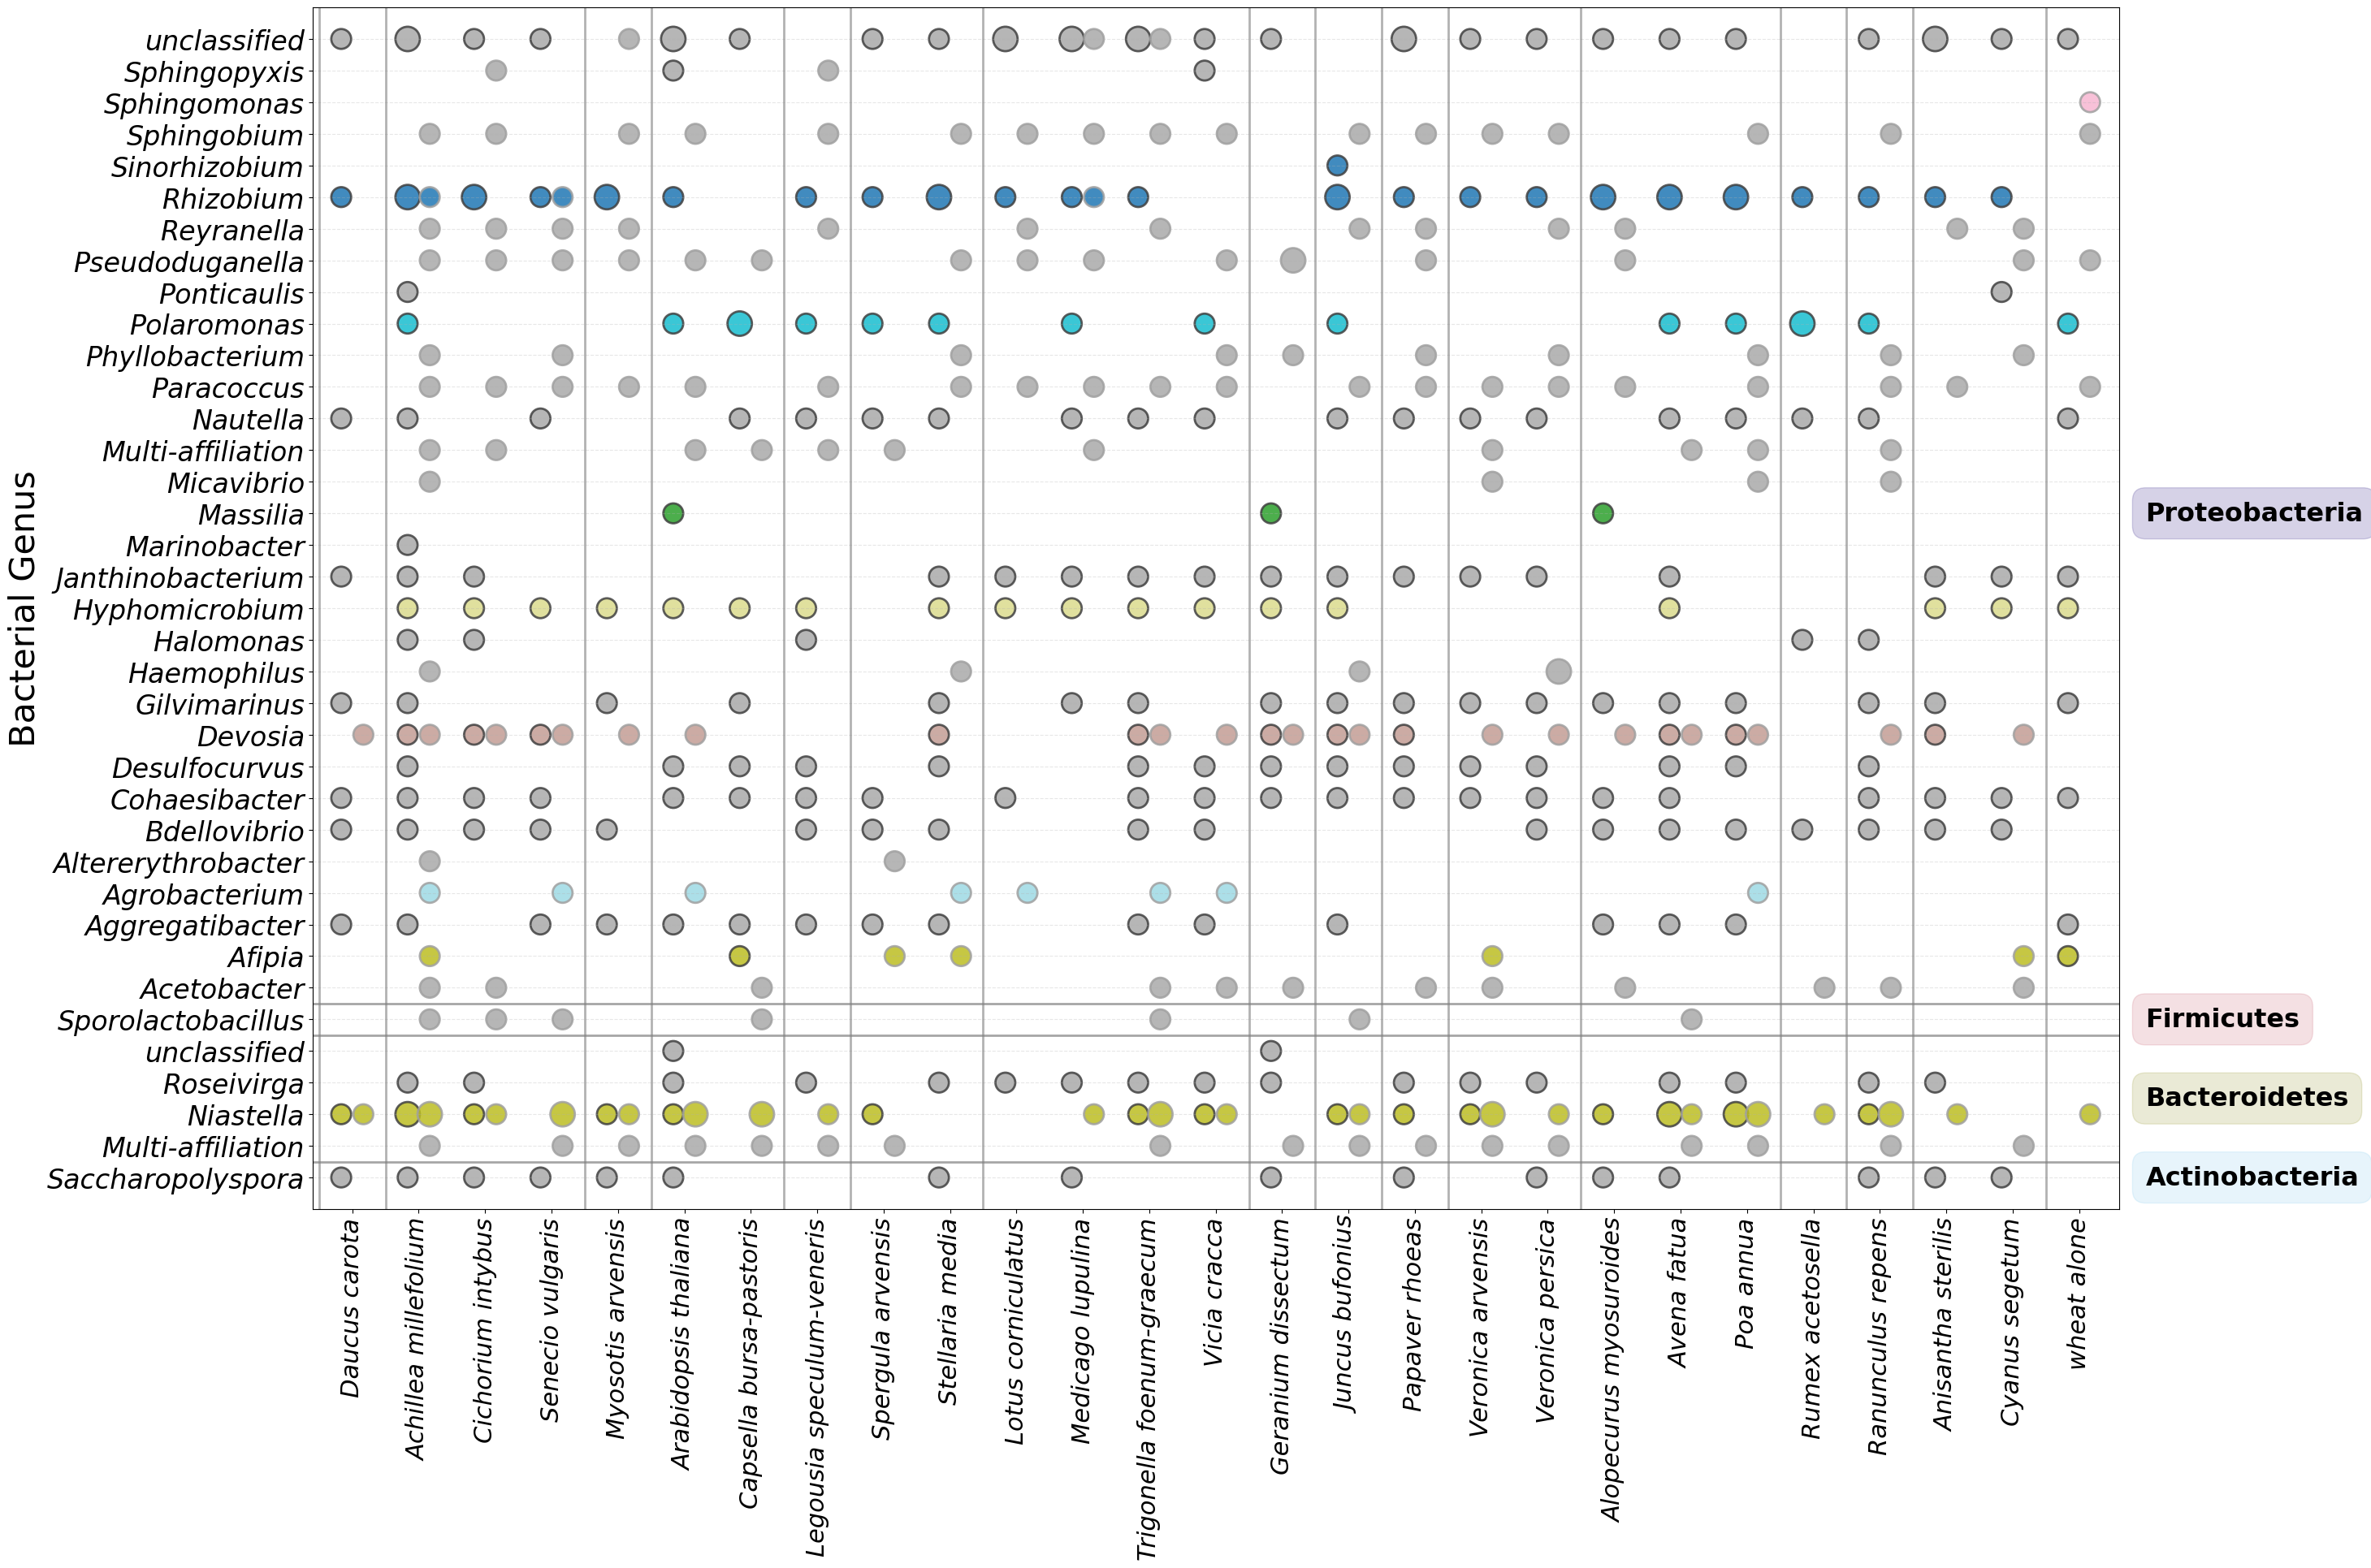

In [18]:
# ============================================================================
#  Bacteria genera dot-plot — revised, parameterised (single notebook cell)
#  Fixes: (1) figure-size & (2) y-axis-size knobs, (3) larger markers,
#         (4) no empty leading column, (5) phylum labels outside the box,
#         (6) corrected + de-capitalised species names on the x-axis.
#  Assumes these already exist in your notebook:
#     filtered_df, cluster_2_genus_d, cluster_2_phylum_d, plant_2_family,
#     beneficial_genera_d, function_palette, phyl_col_d
# ============================================================================
import pandas as pd
import matplotlib.pyplot as plt

# ---- species-name corrections (key = raw name in YOUR data, lower-cased) ----
SPECIES_RENAME = {
    "centaurea cyanus":    "Cyanus segetum",
    "bromus sterilis":     "Anisantha sterilis",
    "festuca arundinacea": "Lolium arundinaceum",   # only if present in your data
    "wheat alone":         "wheat alone",
    "wheat x wheat":       "wheat x wheat",
}
def format_species_name(raw):
    """Correct known misnamings; else capitalise first letter only
       ('daucus carota' -> 'Daucus carota'; hyphen epithets stay lower)."""
    k = str(raw).strip().lower().replace("_", " ")
    if k in SPECIES_RENAME:            return SPECIES_RENAME[k]
    if k in ("wheat alone", "wheat x wheat"): return k
    return k.capitalize()

def create_combined_bacteria_plot(
        filtered_df, cluster_2_genus_d, cluster_2_phylum_d, plant_2_family,
        beneficial_genera_d, function_palette, phyl_col_d,
        default_genus_color="#A9A9A9",
        # -------------------- TUNABLE KNOBS ---------------------------------
        fig_width=32, fig_height=18,     # (1) figure size, inches
        y_fontsize=17,                   # (2) y-axis (genus) label font size
        x_fontsize=22,                   # x-axis (species) label font size
        point_scale=60, point_base=200,  # (3) marker size = count*scale + base
        phylum_gap=1.2,                  # (5) phylum-label distance right of box
        species_spacing=3,
        out_prefix=None):                # if set: saves png(600dpi)/pdf/svg/csv
    # ---- build genus-level long table ----
    gd = []
    for _, r in filtered_df.iterrows():
        c  = r['Cluster']
        g  = cluster_2_genus_d.get(c, "Unknown")
        ph = cluster_2_phylum_d.get(c, "unidentified")
        gd.append({"Plant Species": r['Plant_Species'], "Genus": g, "Phylum": ph,
                   "Function": beneficial_genera_d.get(g, "Unknown"), "Soil": r['Soil']})
    df = pd.DataFrame(gd)

    # (6) correct + de-capitalise species names
    df["Species"] = df["Plant Species"].apply(format_species_name)
    df["Family"]  = df["Species"].map(lambda s: plant_2_family.get(s, "Unknown"))

    df_plot = (df.groupby(["Family","Species","Genus","Phylum","Function","Soil"])
                 .size().reset_index(name="Cluster_Count"))
    df_plot["Plant_Group"] = df_plot["Family"] + " - " + df_plot["Species"]
    ordered = df_plot.sort_values(["Family","Species"])["Plant_Group"].unique()

    # (4) first plant starts at position 0 -> no empty leading column
    plant_positions, pos = {}, 0
    for pl in ordered:
        plant_positions[pl] = pos; pos += species_spacing
    df_plot["x_pos"] = df_plot.apply(
        lambda r: plant_positions[r["Plant_Group"]] - 0.5 if r["Soil"] == "Resistant"
                  else plant_positions[r["Plant_Group"]] + 0.5, axis=1)

    # order genera within phylum
    uniq_phyla = sorted(df_plot['Phylum'].unique())
    phyla_genera = {p: [] for p in uniq_phyla}
    for _, r in df_plot.drop_duplicates(['Genus','Phylum']).iterrows():
        if r['Genus'] not in phyla_genera[r['Phylum']]:
            phyla_genera[r['Phylum']].append(r['Genus'])
    for p in phyla_genera: phyla_genera[p].sort()
    gpp, yp, phylum_positions = {}, 0, {}
    for p in uniq_phyla:
        phylum_positions[p] = yp
        for g in phyla_genera[p]:
            gpp[(g, p)] = yp; yp += 1
    df_plot['y_pos'] = df_plot.apply(lambda r: gpp.get((r['Genus'], r['Phylum']), 0), axis=1)

    # (1) figure size
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    soil_edge = {"Resistant": "#404040", "Permissive": "#A0A0A0"}
    for soil, edge in soil_edge.items():
        sd = df_plot[df_plot["Soil"] == soil]
        colors = [function_palette.get(f, default_genus_color) for f in sd["Function"]]
        ax.scatter(sd["x_pos"], sd["y_pos"],
                   s=sd["Cluster_Count"] * point_scale + point_base,   # (3) marker size
                   c=colors, marker='o', edgecolor=edge, linewidth=2, alpha=0.85, label=soil)

    # y ticks
    yt, ytl = [], []
    for p in uniq_phyla:
        for g in phyla_genera[p]:
            yt.append(gpp[(g, p)]); ytl.append(g)
    ax.set_yticks(yt); ax.set_yticklabels(ytl, fontsize=y_fontsize, fontstyle='italic')
    ax.set_ylabel("Bacterial Genus", fontsize=y_fontsize + 7)

    # x ticks — corrected names, italic
    xt  = [plant_positions[pl] for pl in ordered]
    xtl = [pl.split(" - ")[1] for pl in ordered]
    ax.set_xticks(xt); ax.set_xticklabels(xtl, rotation=90, fontsize=x_fontsize, fontstyle='italic')

    # phylum band separators
    for p in uniq_phyla[1:]:
        ax.axhline(phylum_positions[p] - 0.5, color='gray', lw=2, alpha=0.7)

    # (5) set limits first, then phylum labels just OUTSIDE the box
    xmax = max(plant_positions.values())
    ax.set_xlim(-species_spacing * 0.6, xmax + species_spacing * 0.6)
    ax.set_ylim(-1, yp)
    x_right = ax.get_xlim()[1]
    for p in uniq_phyla:
        n = len(phyla_genera[p])
        if n == 0: continue
        centre = phylum_positions[p] + n / 2 - 0.5
        ax.text(x_right + phylum_gap, centre, p, fontsize=y_fontsize - 1, fontweight='bold',
                va='center', ha='left', clip_on=False,
                bbox=dict(facecolor=phyl_col_d.get(p, "#7f7f7f"), alpha=0.2,
                          edgecolor=phyl_col_d.get(p, "#7f7f7f"), boxstyle="round,pad=0.5"))

    # family separators
    cur = None
    for pl in ordered:
        fam = pl.split(' - ')[0]
        if fam != cur:
            ax.axvline(plant_positions[pl] - 1.5, color='gray', lw=2, alpha=0.6); cur = fam

    # legends
    soil_leg = [
        plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='gray',
                   markeredgecolor='#404040', markeredgewidth=2, markersize=13, label='Cereal-dominated Soil'),
        plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='gray',
                   markeredgecolor='#A0A0A0', markeredgewidth=2, markersize=13, label='Mixed-system Soil')]
    func_leg = [plt.Line2D([0],[0], marker='o', color='w', markerfacecolor=c, markersize=15, label=f)
                for f, c in function_palette.items() if f in df_plot["Function"].values]
    if "Unknown" in df_plot["Function"].values:
        func_leg.append(plt.Line2D([0],[0], marker='o', color='w',
                        markerfacecolor=default_genus_color, markersize=13, label="Unknown Function"))
    # ax.legend(handles=soil_leg + func_leg, bbox_to_anchor=(1.10, 1), loc="upper left",
    #           title="Soil Type & Function", title_fontsize=16, fontsize=13, frameon=True)

    ax.grid(axis='y', linestyle='--', alpha=0.3)
    fig.subplots_adjust(right=0.82, bottom=0.22, top=0.96)

    if out_prefix:
        fig.savefig(out_prefix + ".png", dpi=600, bbox_inches='tight')
        fig.savefig(out_prefix + ".pdf", bbox_inches='tight')
        fig.savefig(out_prefix + ".svg", bbox_inches='tight')
        df_plot.to_csv(out_prefix + ".csv", index=False)
    return fig, df_plot

# ---- run + display inline ----
fig, df_plot = create_combined_bacteria_plot(
    filtered_df, cluster_2_genus_d, cluster_2_phylum_d, plant_2_family,
    beneficial_genera_d, function_palette, phyl_col_d,
    fig_width=32, fig_height=20,      # <<< change figure size here
    y_fontsize=24,                    # <<< change y-axis label size here
    point_scale=80, point_base=150,   # <<< change marker size here
    # out_prefix=os.path.join(output_dir, "bacteria_genera_by_phyla_combined_soils"),
)
plt.show()